# 02 – Визуализация данных Европы

Цель – показать состав, покрытие и диагностические группы исходного набора перед выбором правил очистки. Все 20 аэропортов сохраняются. Графики рассчитаны по полной базе, исходный файл не изменяется.

Источник: [Zenodo 10210178](https://zenodo.org/records/10210178), DOI `10.5281/zenodo.10210178`. Проверенный период посадок – январь 2019 – май 2023. Метка `GoA` означает хотя бы один отмеченный уход, а не опасность аэропорта. Полные траектории и погода отсутствуют.

Каждый график создается отдельной ячейкой и сохраняется в PNG и SVG. Графики с интервалами используют прежний математический шаблон Уилсона 95% без критерия исключения аэропортов. Интервалы условны относительно независимости записей; повторные борта и неоднородность покрытия отдельно не учтены.

In [1]:
from pathlib import Path
import json, sys, runpy, hashlib
from statistics import NormalDist
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Image, Markdown

ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'europe/data/source/osn23_landings_merged.parquet.gzip').exists() and (p/'.git').exists())
R=ROOT/'europe';REPORTS=R/'reports';V=REPORTS/'visualization';FIGURES=R/'figures';FIGURES.mkdir(exist_ok=True)
# Пересчитываем дополнительные агрегаты по неизмененному источнику
runpy.run_path(str(R/'scripts/prepare_visualization.py'),run_name='__main__')
summary=json.loads((REPORTS/'profile_summary.json').read_text(encoding='utf8'))
extra=json.loads((V/'summary.json').read_text(encoding='utf8'))
assert summary['source_sha256']==extra['source_sha256'] and extra['source_unchanged']
ORANGE='#FF6B00';GRAY='#65718A'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':16,'axes.spines.top':False,
 'axes.spines.right':False,'figure.facecolor':'white','axes.facecolor':'white','figure.dpi':120})
COUNTRIES={'Austria':'Австрия','Denmark':'Дания','France':'Франция','Germany':'Германия','Ireland':'Ирландия','Italy':'Италия',
 'Netherlands':'Нидерланды','Poland':'Польша','Spain':'Испания','Sweden':'Швеция','Switzerland':'Швейцария','Turkey':'Турция','United Kingdom':'Великобритания'}
FREQ_NOTE='Интервалы Уилсона 95% при условной независимости записей'
def read(name):return pd.read_csv(REPORTS/name,keep_default_na=False)
def wilson(k,n):
 k=np.asarray(k,dtype=float);n=np.asarray(n,dtype=float);z=NormalDist().inv_cdf(.975)
 p=k/n;den=1+z*z/n;center=(p+z*z/(2*n))/den;half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
 return 100*(center-half),100*(center+half)
def chart(title,subtitle='',size=(15,8)):
 fig,ax=plt.subplots(figsize=size);fig.suptitle(title,fontsize=26,fontweight='bold',y=.98)
 if subtitle:ax.set_title(subtitle,fontsize=13,color=GRAY,pad=20)
 ax.set_axisbelow(True);return fig,ax
def save(fig,name):
 fig.tight_layout(rect=[0,0,1,.93]);fig.savefig(FIGURES/(name+'.png'),dpi=200,bbox_inches='tight',facecolor='white')
 fig.savefig(FIGURES/(name+'.svg'),bbox_inches='tight',facecolor='white')
 plt.close(fig);display(Image(filename=str(FIGURES/(name+'.png'))))
def labels(frame):return frame['airport']+' – '+frame['city']
def dates(ax):
 ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4));ax.xaxis.set_major_formatter(mdates.DateFormatter('%m.%Y'))
 ax.tick_params(axis='x',rotation=45);ax.grid(axis='y',color='#E7EBF1')
def percent_axis(ax,axis='x'):
 formatter=FuncFormatter(lambda x,pos:f'{x:.1f}'.replace('.',','))
 (ax.xaxis if axis=='x' else ax.yaxis).set_major_formatter(formatter)
print('Исходных записей:',f"{summary['rows']:,}")
print('Очистка не выполнялась; отчеты относятся ко всей исходной базе.')

{
  "rows": 7984254,
  "source_sha256": "1160bdbea6fa93249a00768452be64047c6d2461bb0843d5ecfc52e6942c7f02",
  "source_unchanged": true,
  "rows_deleted": 0,
  "joint_null_mask_equal_AC_CLASS_C40": true,
  "days_without_records_at_all_20_airports": [
    "2022-08-31",
    "2022-11-03",
    "2022-11-09",
    "2022-11-18",
    "2022-11-23",
    "2022-12-04",
    "2022-12-15",
    "2022-12-18",
    "2022-12-21",
    "2022-12-22",
    "2022-12-23",
    "2022-12-24",
    "2022-12-25",
    "2022-12-26",
    "2022-12-27",
    "2022-12-28",
    "2022-12-29",
    "2022-12-30",
    "2022-12-31",
    "2023-01-02",
    "2023-02-23"
  ],
  "c40_availability": [
    {
      "c40_available": false,
      "rows": 1652382,
      "go_arounds": 7847,
      "ga_percent": 0.47489018883042783
    },
    {
      "c40_available": true,
      "rows": 6331872,
      "go_arounds": 18406,
      "ga_percent": 0.2906881250916001
    }
  ],
  "missingness_definition": "physical null or exact empty string; whitespace 

Исходных записей: 7,984,254
Очистка не выполнялась; отчеты относятся ко всей исходной базе.


## Географический состав

Показываем страны выборки авторов. Кол-во наблюдений не равно фактической интенсивности движения. Европейский охват источника не означает единых процедур и условий во всех аэропортах.

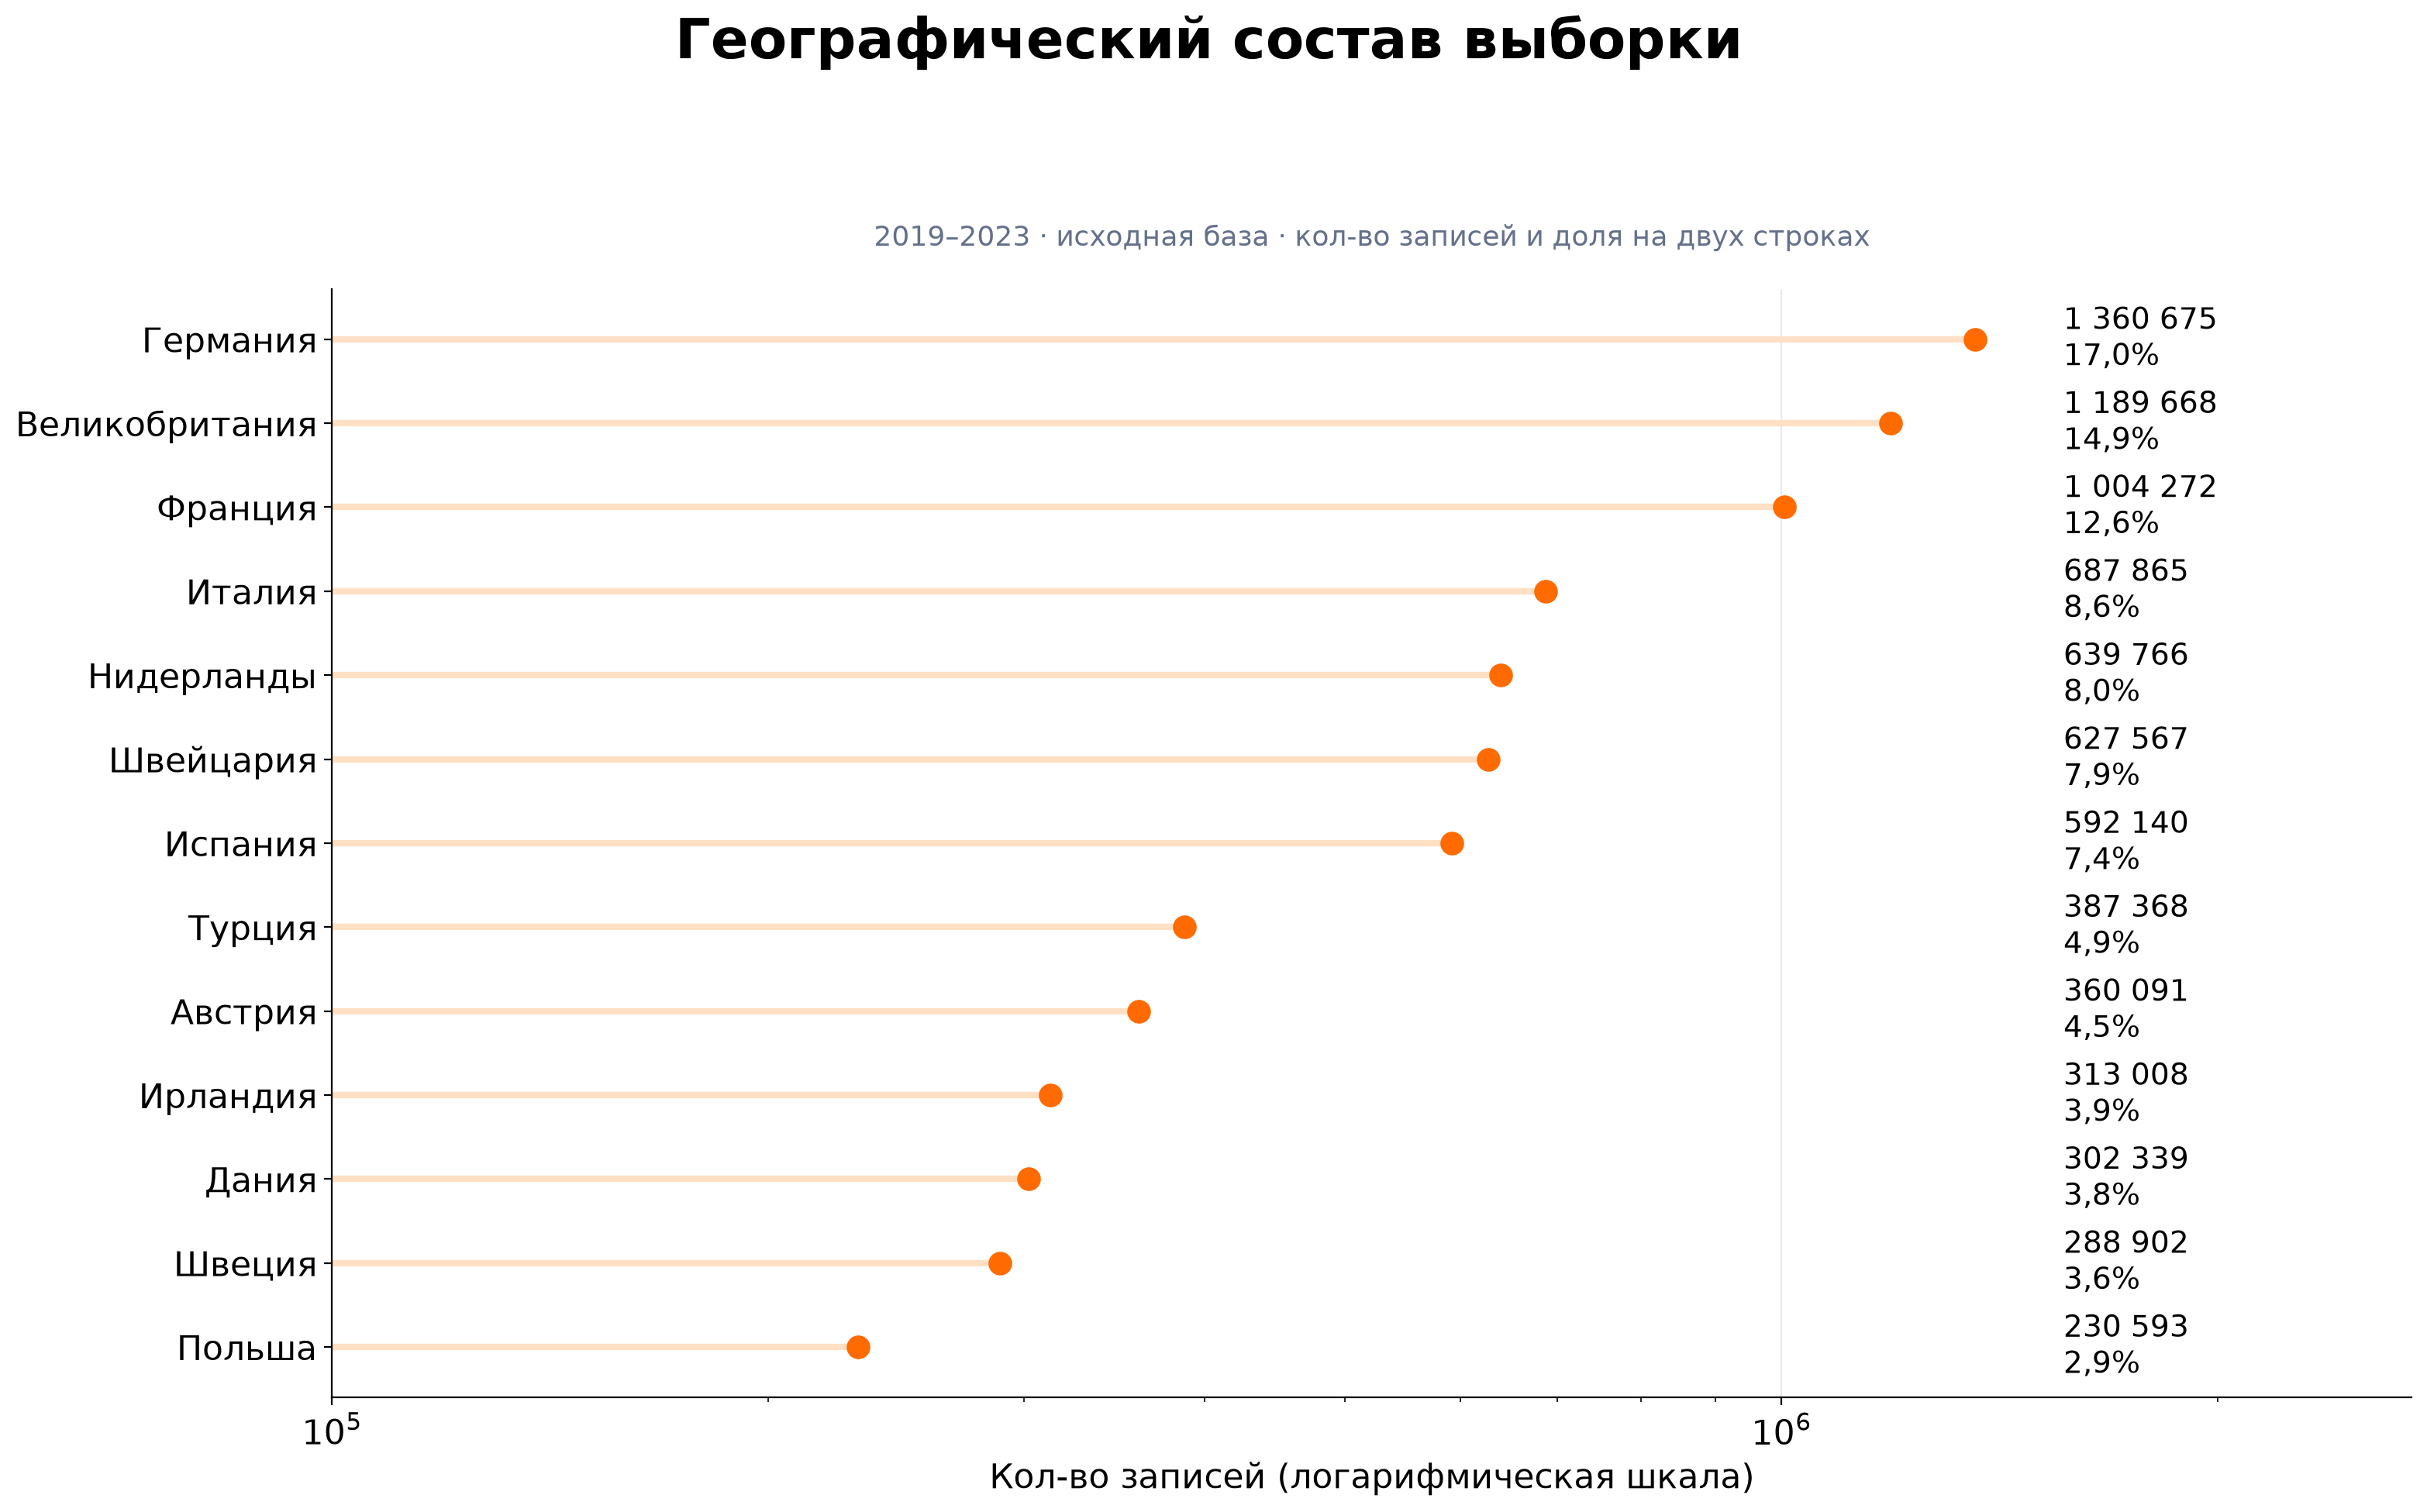

In [2]:
country=read('country_summary.csv').sort_values('rows',ascending=False).reset_index(drop=True)
fig,ax=chart('Географический состав выборки','2019–2023 · исходная база · кол-во записей и доля на двух строках',size=(16,10))
y=np.arange(len(country));ax.hlines(y,100000,country['rows'],color='#FFE0C4',lw=3)
ax.scatter(country['rows'],y,color=ORANGE,s=100,zorder=3);ax.set_xscale('log');ax.set_yticks(y,country['country'].map(COUNTRIES));ax.invert_yaxis()
ax.set_xlim(100000,country['rows'].max()*2);ax.set_xlabel('Кол-во записей (логарифмическая шкала)');ax.grid(axis='x',color='#E7EBF1')
for i,row in country.iterrows():ax.text(country['rows'].max()*1.15,i,f"{int(row['rows']):,}".replace(',',' ')+f"\n{100*row['rows']/summary['rows']:.1f}%".replace('.',','),va='center',fontsize=14)
save(fig,'01_geographic_composition')

## Покрытие и частоты по аэропортам

Все аэропорты показаны без исключений. Различие наблюдаемых частот может отражать состав полетов, покрытие и разметку. Интервалы на следующем графике не учитывают зависимость повторных бортов и не являются рейтингом безопасности.

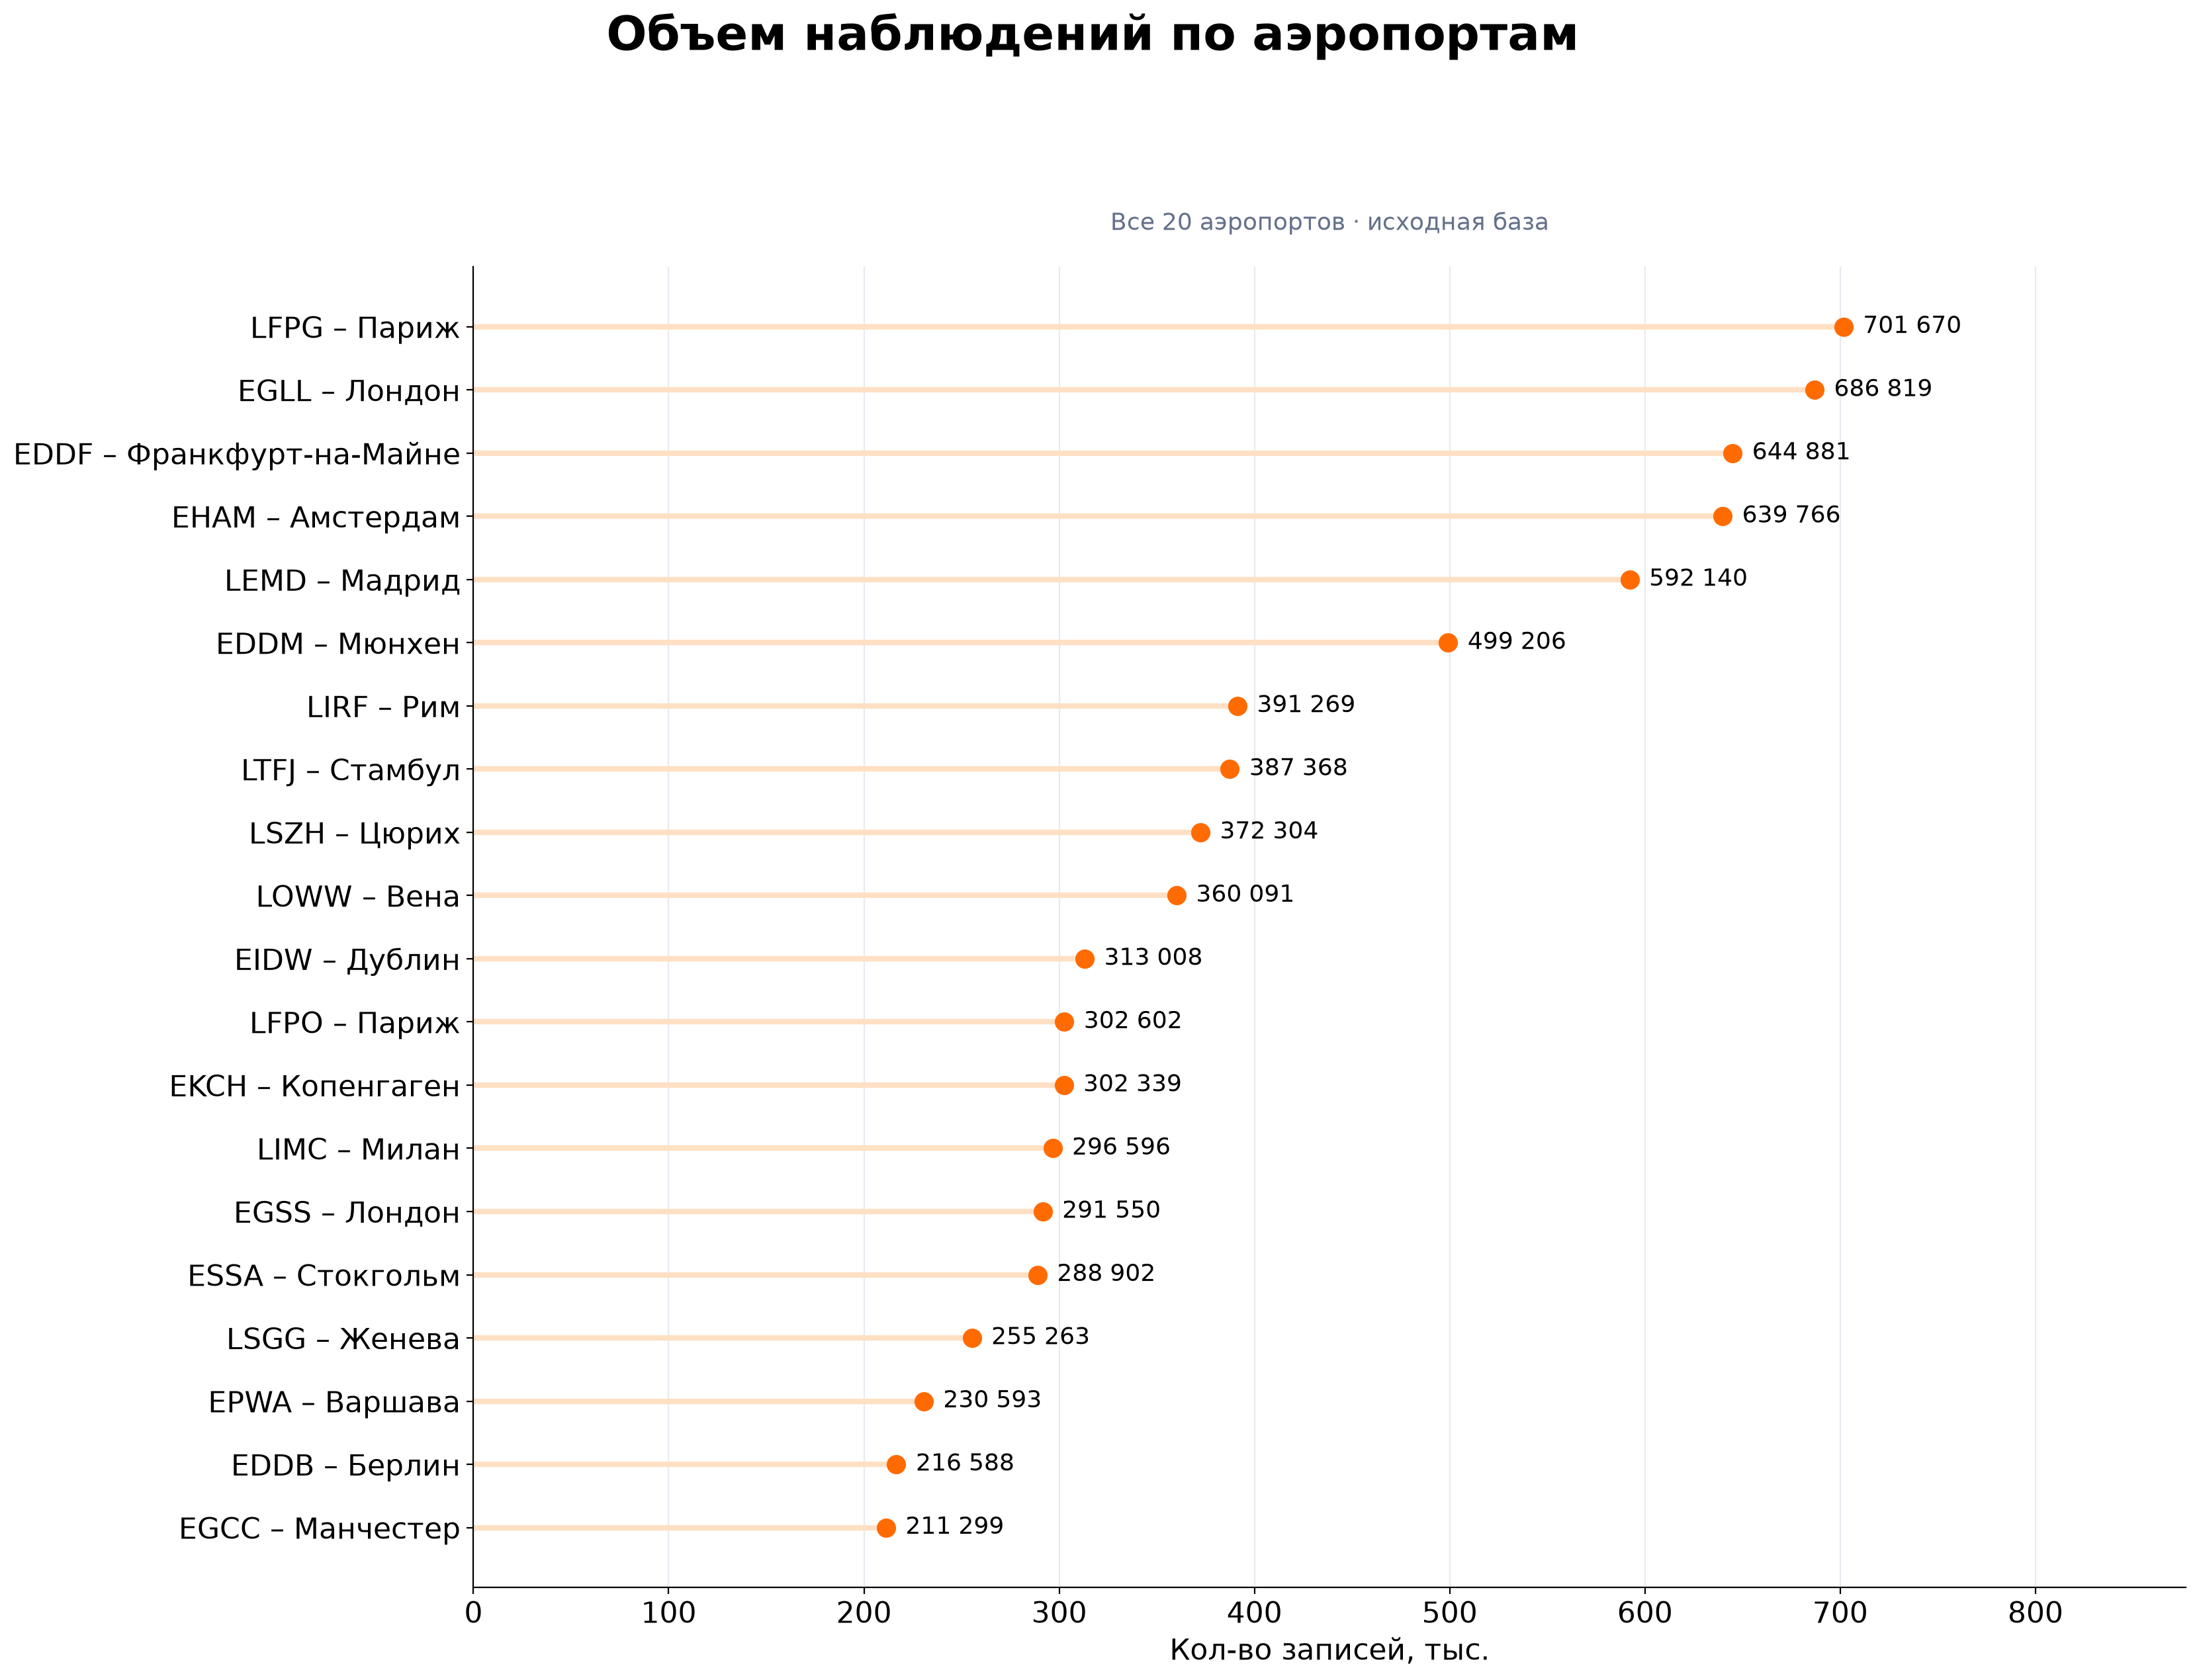

In [3]:
airports=read('airport_summary.csv').sort_values('rows',ascending=False).reset_index(drop=True)
fig,ax=chart('Объем наблюдений по аэропортам','Все 20 аэропортов · исходная база',size=(17,13))
y=np.arange(len(airports));ax.hlines(y,0,airports['rows']/1000,color='#FFE0C4',lw=3)
ax.scatter(airports['rows']/1000,y,color=ORANGE,s=90,zorder=3);ax.set_yticks(y,labels(airports));ax.invert_yaxis()
ax.set_xlim(0,airports['rows'].max()/1000*1.25);ax.set_xlabel('Кол-во записей, тыс.');ax.grid(axis='x',color='#E7EBF1')
for i,row in airports.iterrows():ax.text(row['rows']/1000+10,i,f"{int(row['rows']):,}".replace(',',' '),va='center',fontsize=13)
save(fig,'02_airport_coverage')

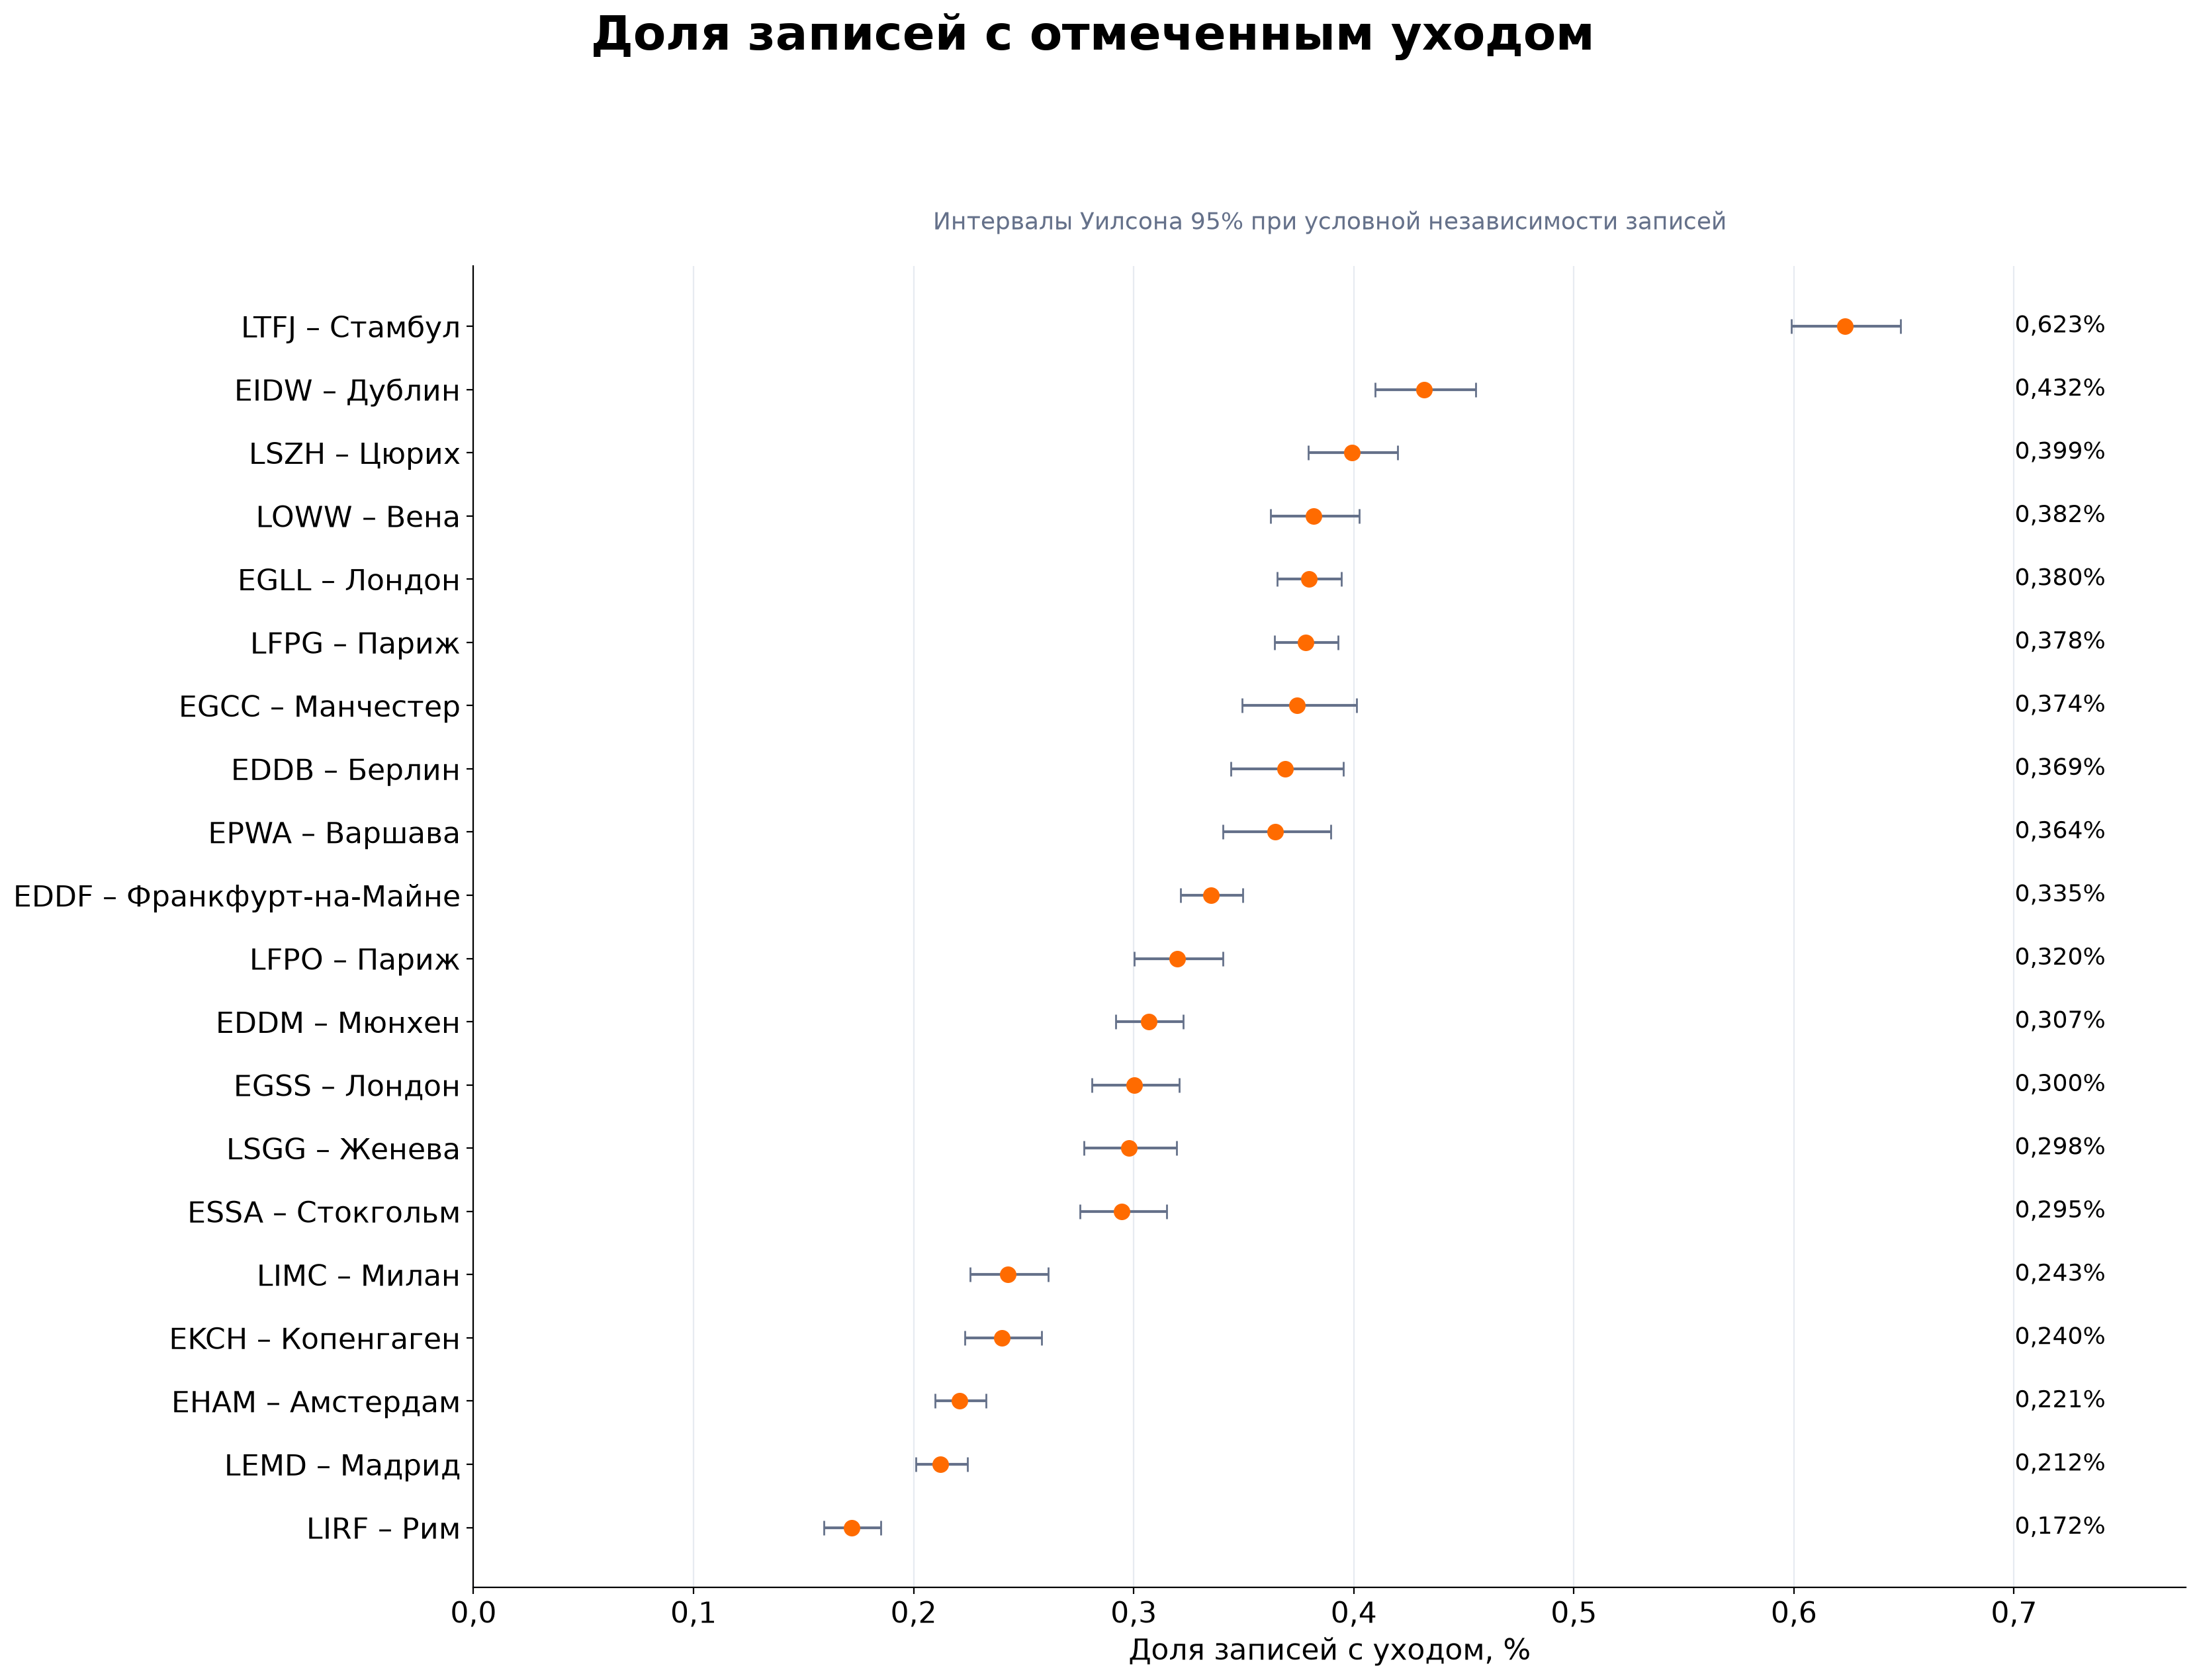

In [4]:
rates=airports.sort_values('ga_percent',ascending=False).reset_index(drop=True)
lo,hi=wilson(rates['go_arounds'],rates['rows']);p=rates['ga_percent'].to_numpy()
fig,ax=chart('Доля записей с отмеченным уходом',FREQ_NOTE,size=(17,13))
y=np.arange(len(rates));ax.errorbar(p,y,xerr=[p-lo,hi-p],fmt='o',color=ORANGE,ecolor=GRAY,capsize=4,markersize=8,barsabove=False)
ax.set_yticks(y,labels(rates));ax.invert_yaxis();ax.set_xlim(0,max(hi)*1.2);ax.set_xlabel('Доля записей с уходом, %');percent_axis(ax);ax.grid(axis='x',color='#E7EBF1')
for i,row in rates.iterrows():ax.text(max(hi)*1.08,i,f"{row['ga_percent']:.3f}%".replace('.',','),va='center',fontsize=13)
pd.DataFrame({'airport':rates['airport'],'rows':rates['rows'],'go_arounds':rates['go_arounds'],'ga_percent':p,'wilson_low_percent':lo,'wilson_high_percent':hi}).to_csv(V/'airport_frequency_intervals.csv',index=False)
save(fig,'03_airport_goaround_frequency')

## Изменение объема и доли событий во времени

Объем наблюдений и доля уходов показаны раздельно. Снижение числа записей само по себе не доказывает ухудшение покрытия. 2023 год неполный. Любое объяснение всплесков погодой или изменением движения требует независимых данных.

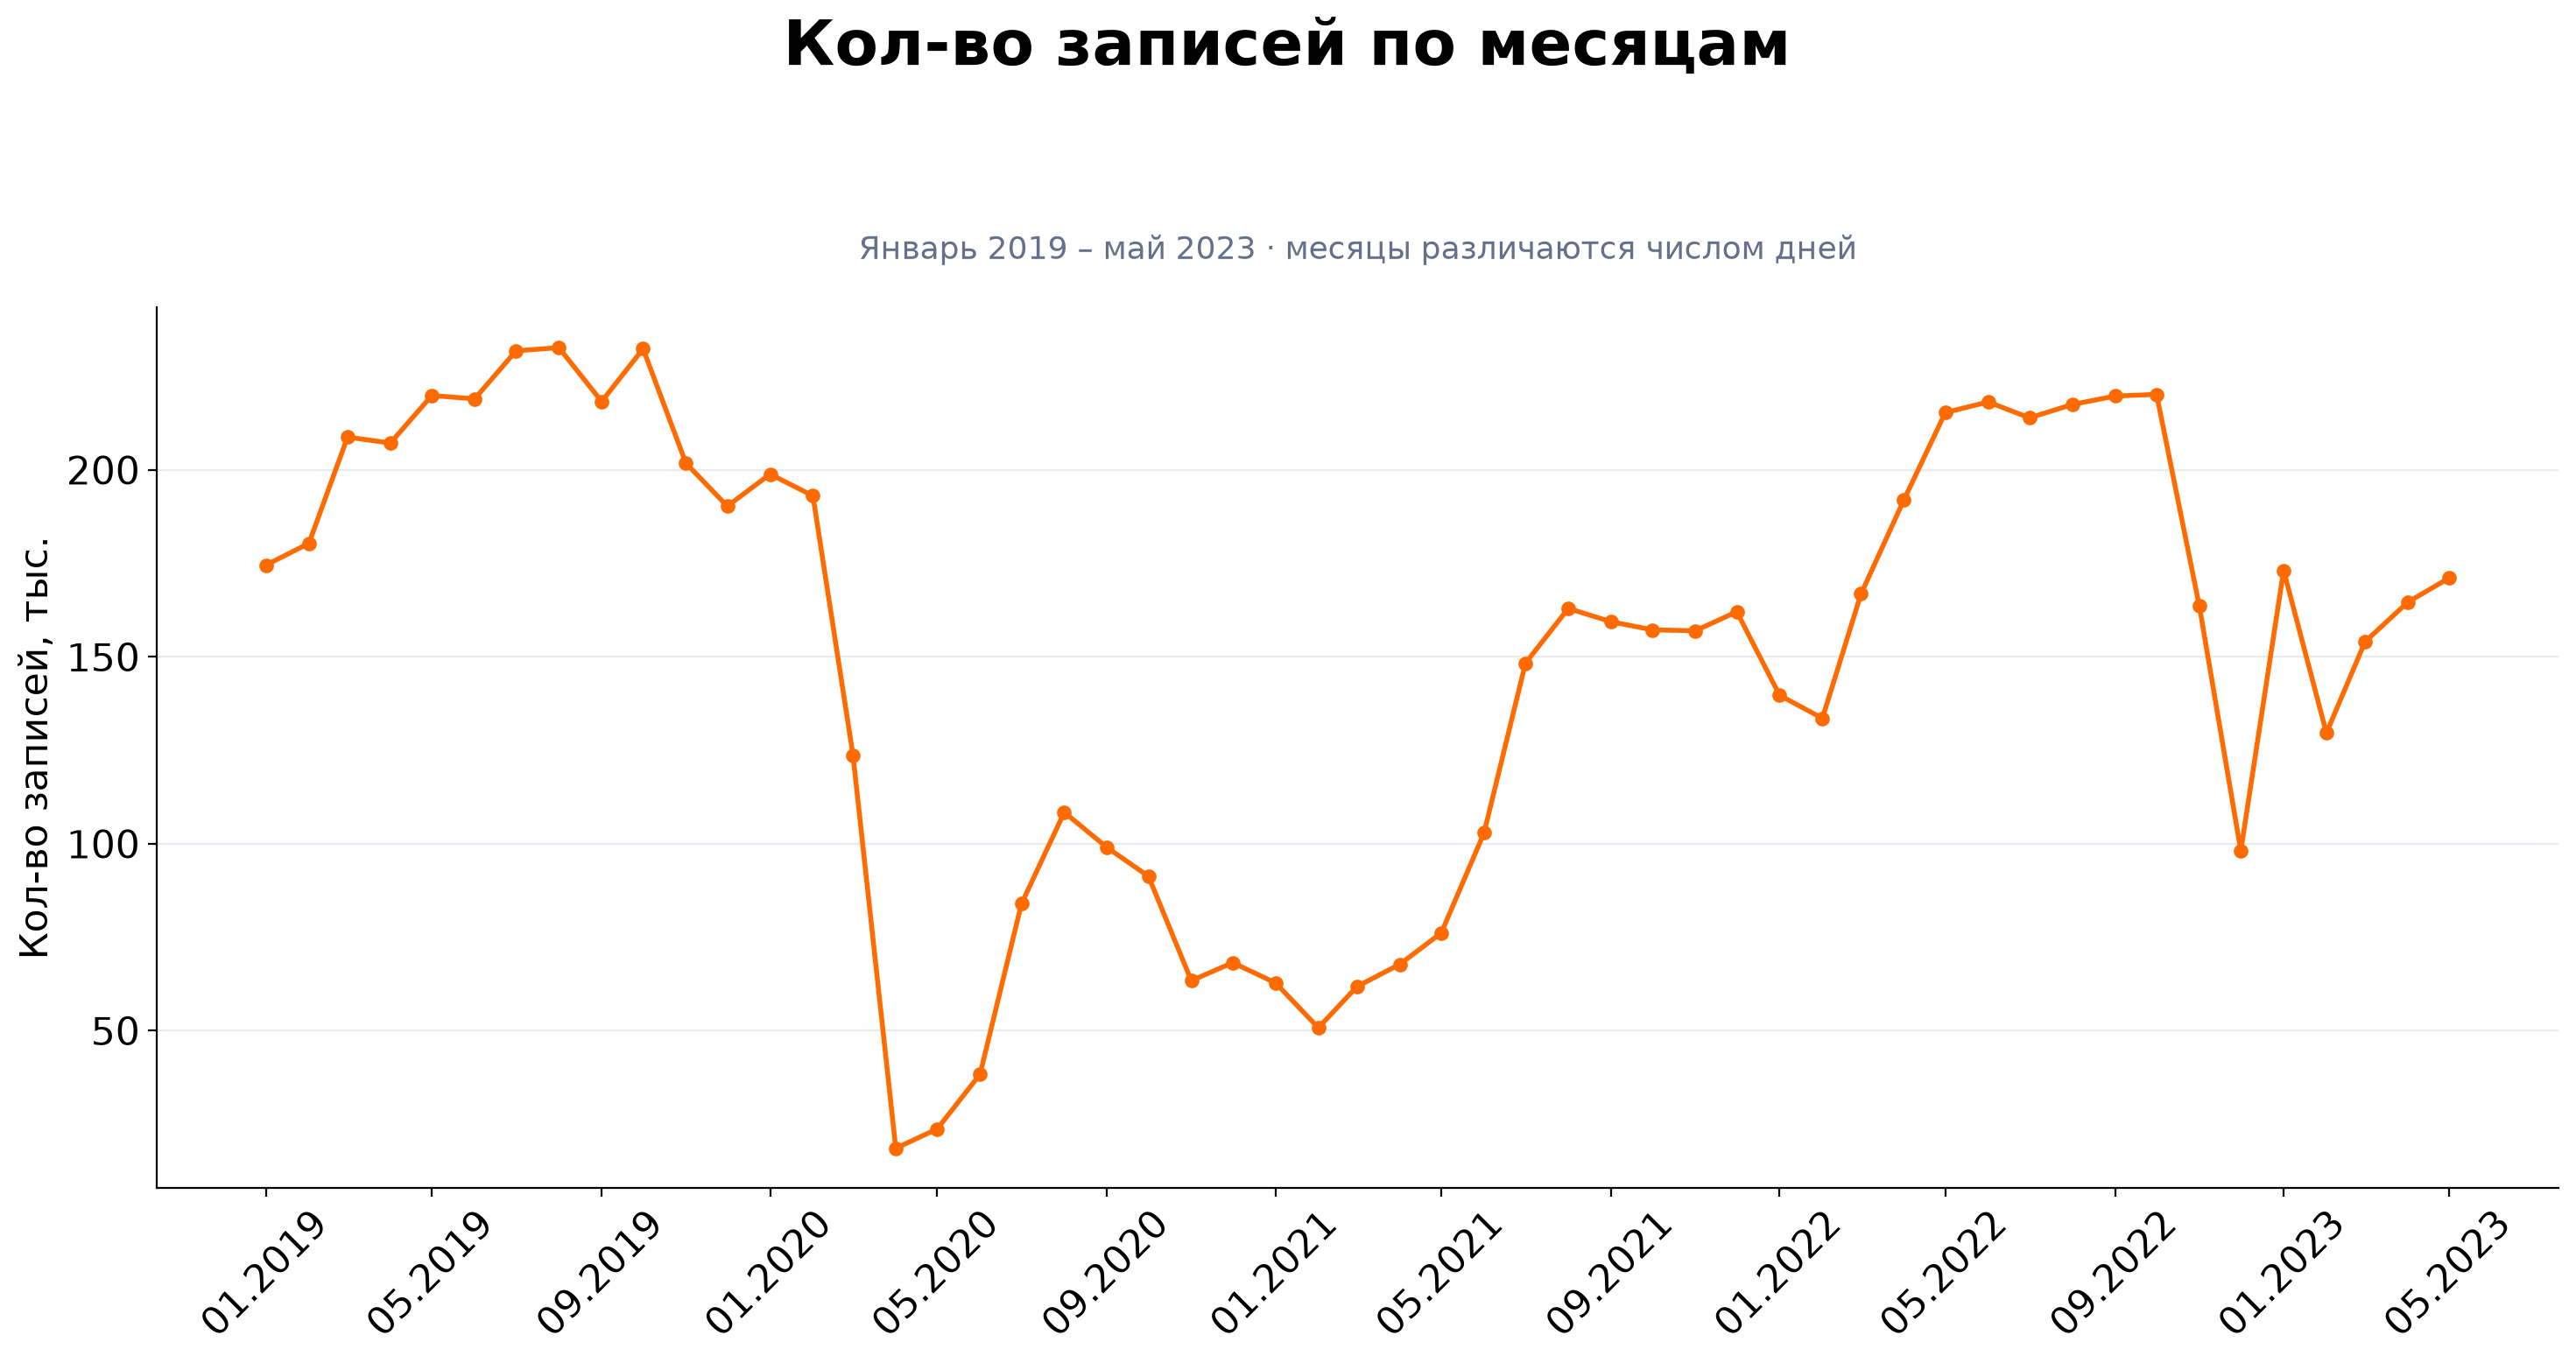

In [5]:
monthly=read('month_summary.csv');x=pd.to_datetime(monthly['month'])
fig,ax=chart('Кол-во записей по месяцам','Январь 2019 – май 2023 · месяцы различаются числом дней')
ax.plot(x,monthly['rows']/1000,color=ORANGE,marker='o',ms=5,lw=2);ax.set_ylabel('Кол-во записей, тыс.');dates(ax)
save(fig,'04_monthly_volume')

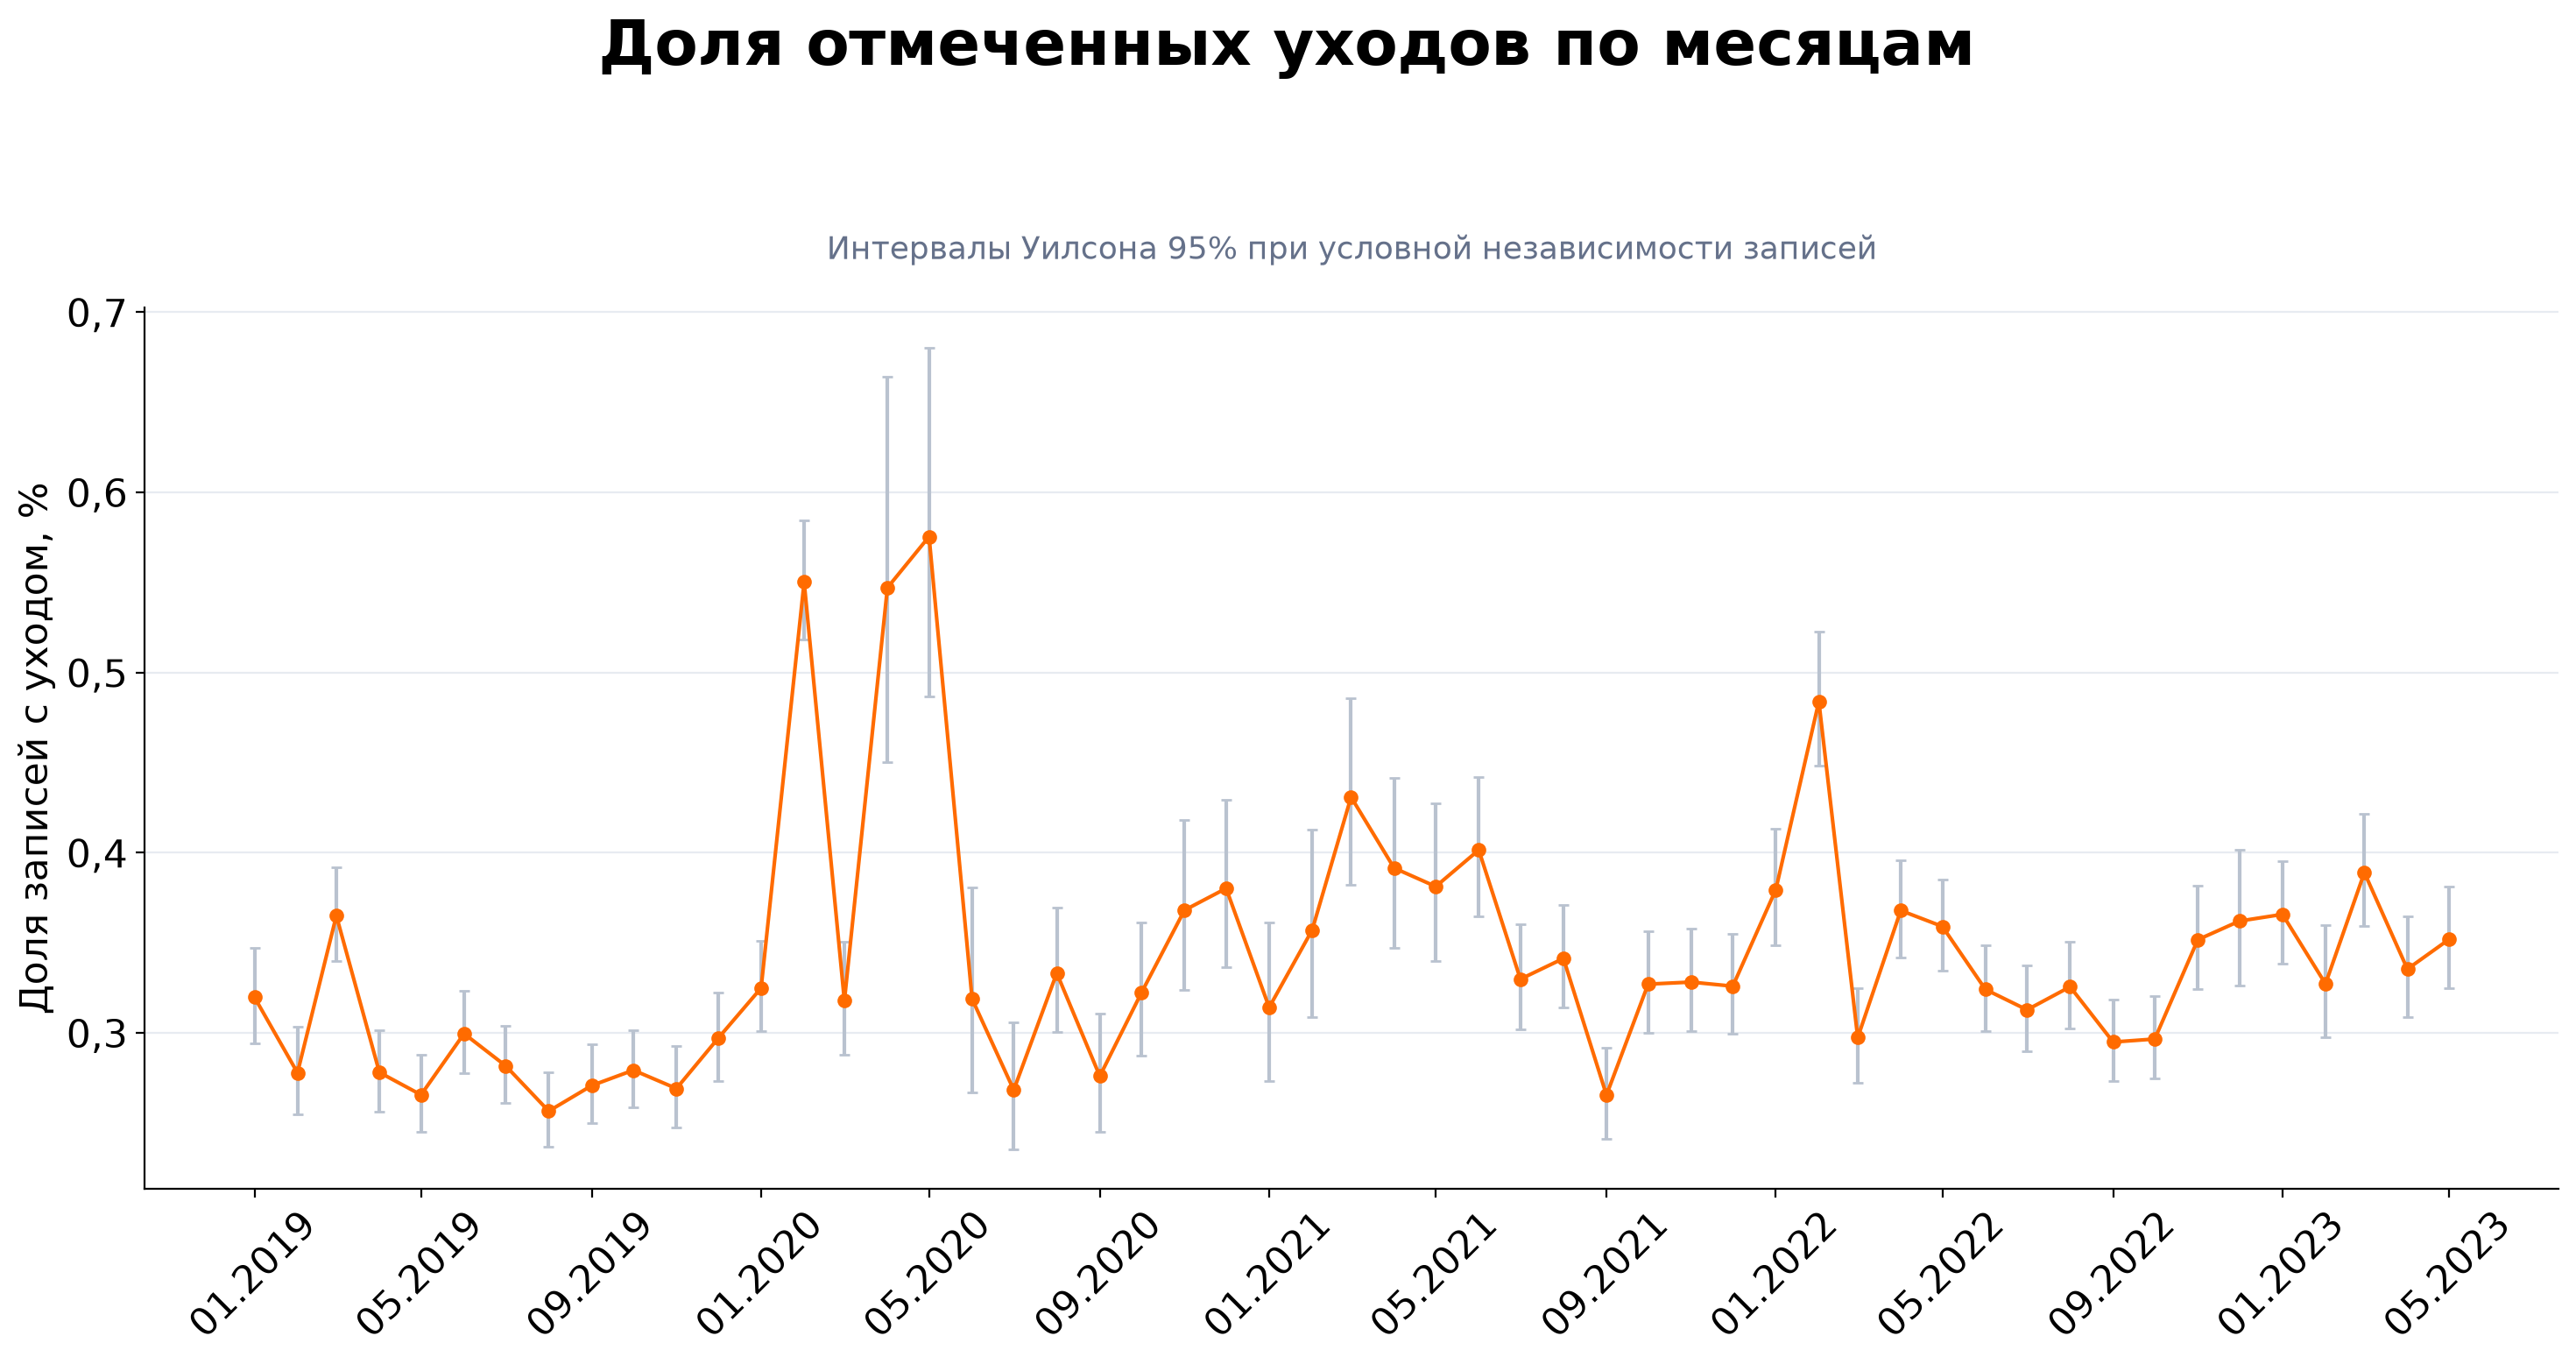

In [6]:
lo,hi=wilson(monthly['go_arounds'],monthly['rows']);p=monthly['ga_percent'].to_numpy()
fig,ax=chart('Доля отмеченных уходов по месяцам',FREQ_NOTE)
ax.errorbar(x,p,yerr=[p-lo,hi-p],fmt='o-',color=ORANGE,ecolor='#B9C2CF',capsize=2,ms=5,lw=1.5,barsabove=False)
ax.set_ylabel('Доля записей с уходом, %');percent_axis(ax,'y');dates(ax)
save(fig,'05_monthly_goaround_frequency')

## Пропуски и обогащение

Физический null и пустая строка показаны отдельно. Совпадение масок пропусков разных полей может указывать на общий этап обогащения; его причина пока не установлена.

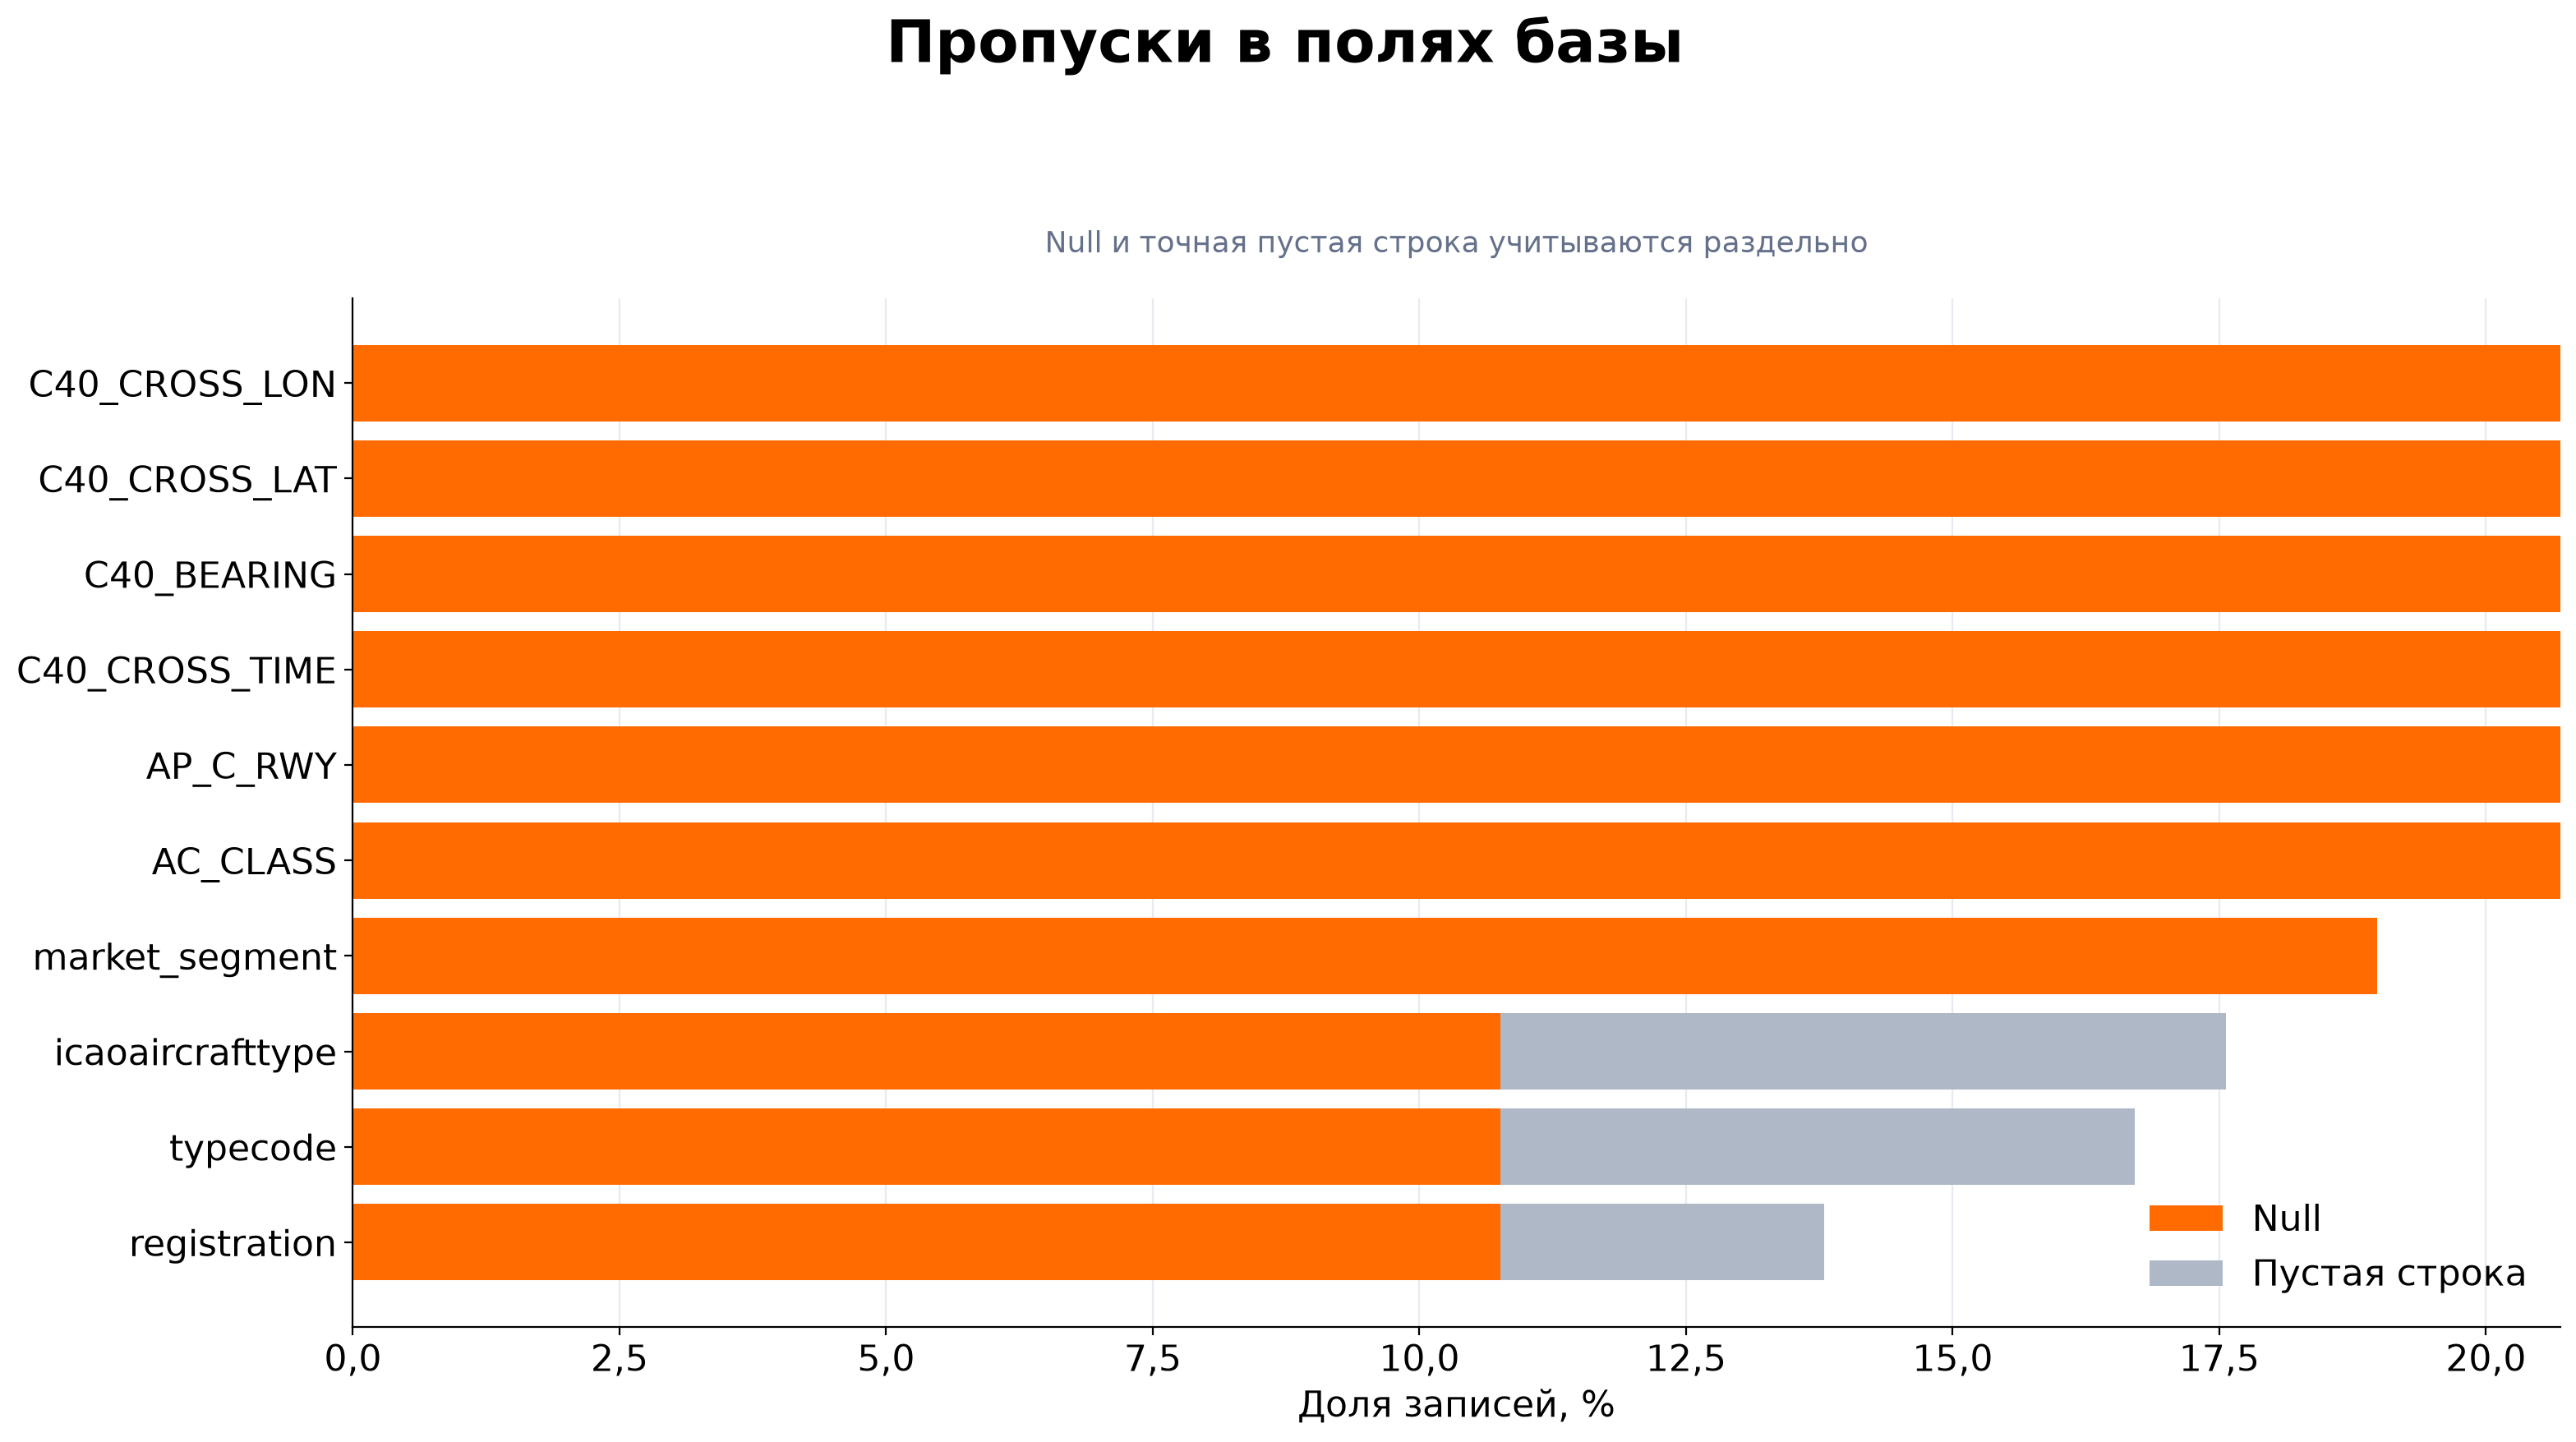

In [8]:
missing=read('missingness.csv');missing=missing.loc[(missing['null_count']+missing['empty_string_count'])>0].copy()
missing['empty_percent']=100*missing['empty_string_count']/summary['rows'];missing=missing.sort_values('null_percent',ascending=True)
fig,ax=chart('Пропуски в полях базы','Null и точная пустая строка учитываются раздельно',size=(16,9))
ax.barh(missing['column'],missing['null_percent'],color=ORANGE,label='Null');ax.barh(missing['column'],missing['empty_percent'],left=missing['null_percent'],color='#AEB8C6',label='Пустая строка')
ax.set_xlabel('Доля записей, %');percent_axis(ax);ax.legend(frameon=False);ax.grid(axis='x',color='#E7EBF1')
save(fig,'07_missingness')

## Различие групп по наличию C40

Сравнение показывает наблюдаемую связь наличия обогащения и метки. Оно не устанавливает влияние самого обогащения и не корректирует различия аэропортов, времени и состава самолетов. Такой результат может быть основанием отдельно изучить смещение отбора.

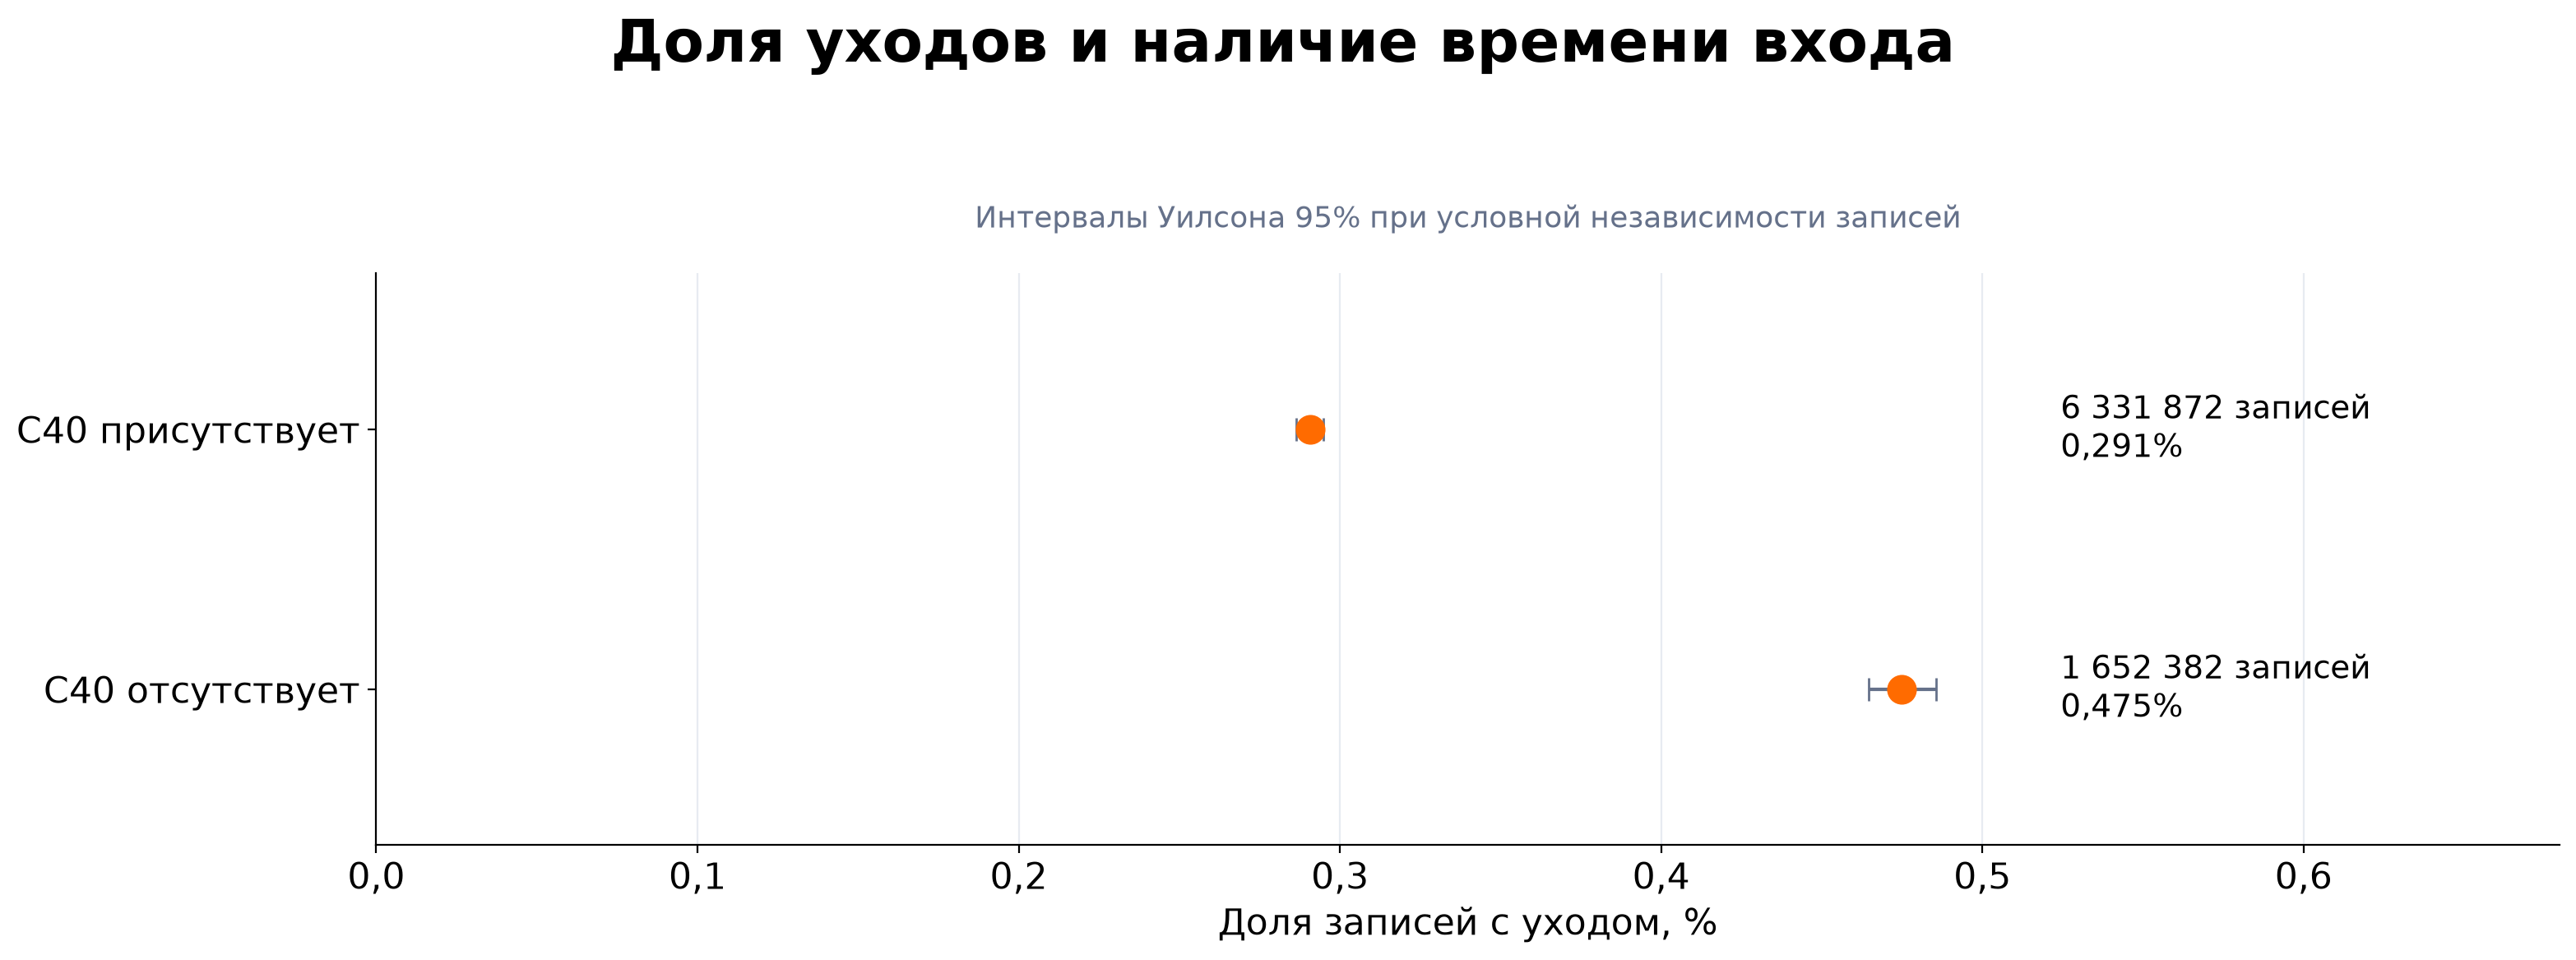

In [10]:
available=pd.read_csv(V/'c40_availability.csv');lo,hi=wilson(available['go_arounds'],available['rows']);p=available['ga_percent'].to_numpy()
fig,ax=chart('Доля уходов и наличие времени входа',FREQ_NOTE,size=(16,6))
names=['C40 отсутствует' if not v else 'C40 присутствует' for v in available['c40_available']]
y=np.arange(len(available));ax.errorbar(p,y,xerr=[p-lo,hi-p],fmt='o',color=ORANGE,ecolor=GRAY,capsize=5,ms=12,barsabove=False)
ax.set_yticks(y,names);ax.set_xlim(0,max(hi)*1.4);ax.set_xlabel('Доля записей с уходом, %');percent_axis(ax);ax.grid(axis='x',color='#E7EBF1')
ax.set_ylim(-.6,1.6)
for i,row in available.iterrows():ax.text(max(hi)*1.08,i,f"{int(row['rows']):,} записей".replace(',',' ')+f"\n{row['ga_percent']:.3f}%".replace('.',','),va='center',fontsize=14)
save(fig,'09_c40_availability_frequency')

## Количество попыток и состав самолетов

Все исходные значения количества попыток сохранены. Логарифмическая шкала позволяет увидеть редкие большие значения. Больше двух попыток не считается доказательством учебного назначения полета. Неизвестный тип самолета не приравнивается к учебному или коммерческому.

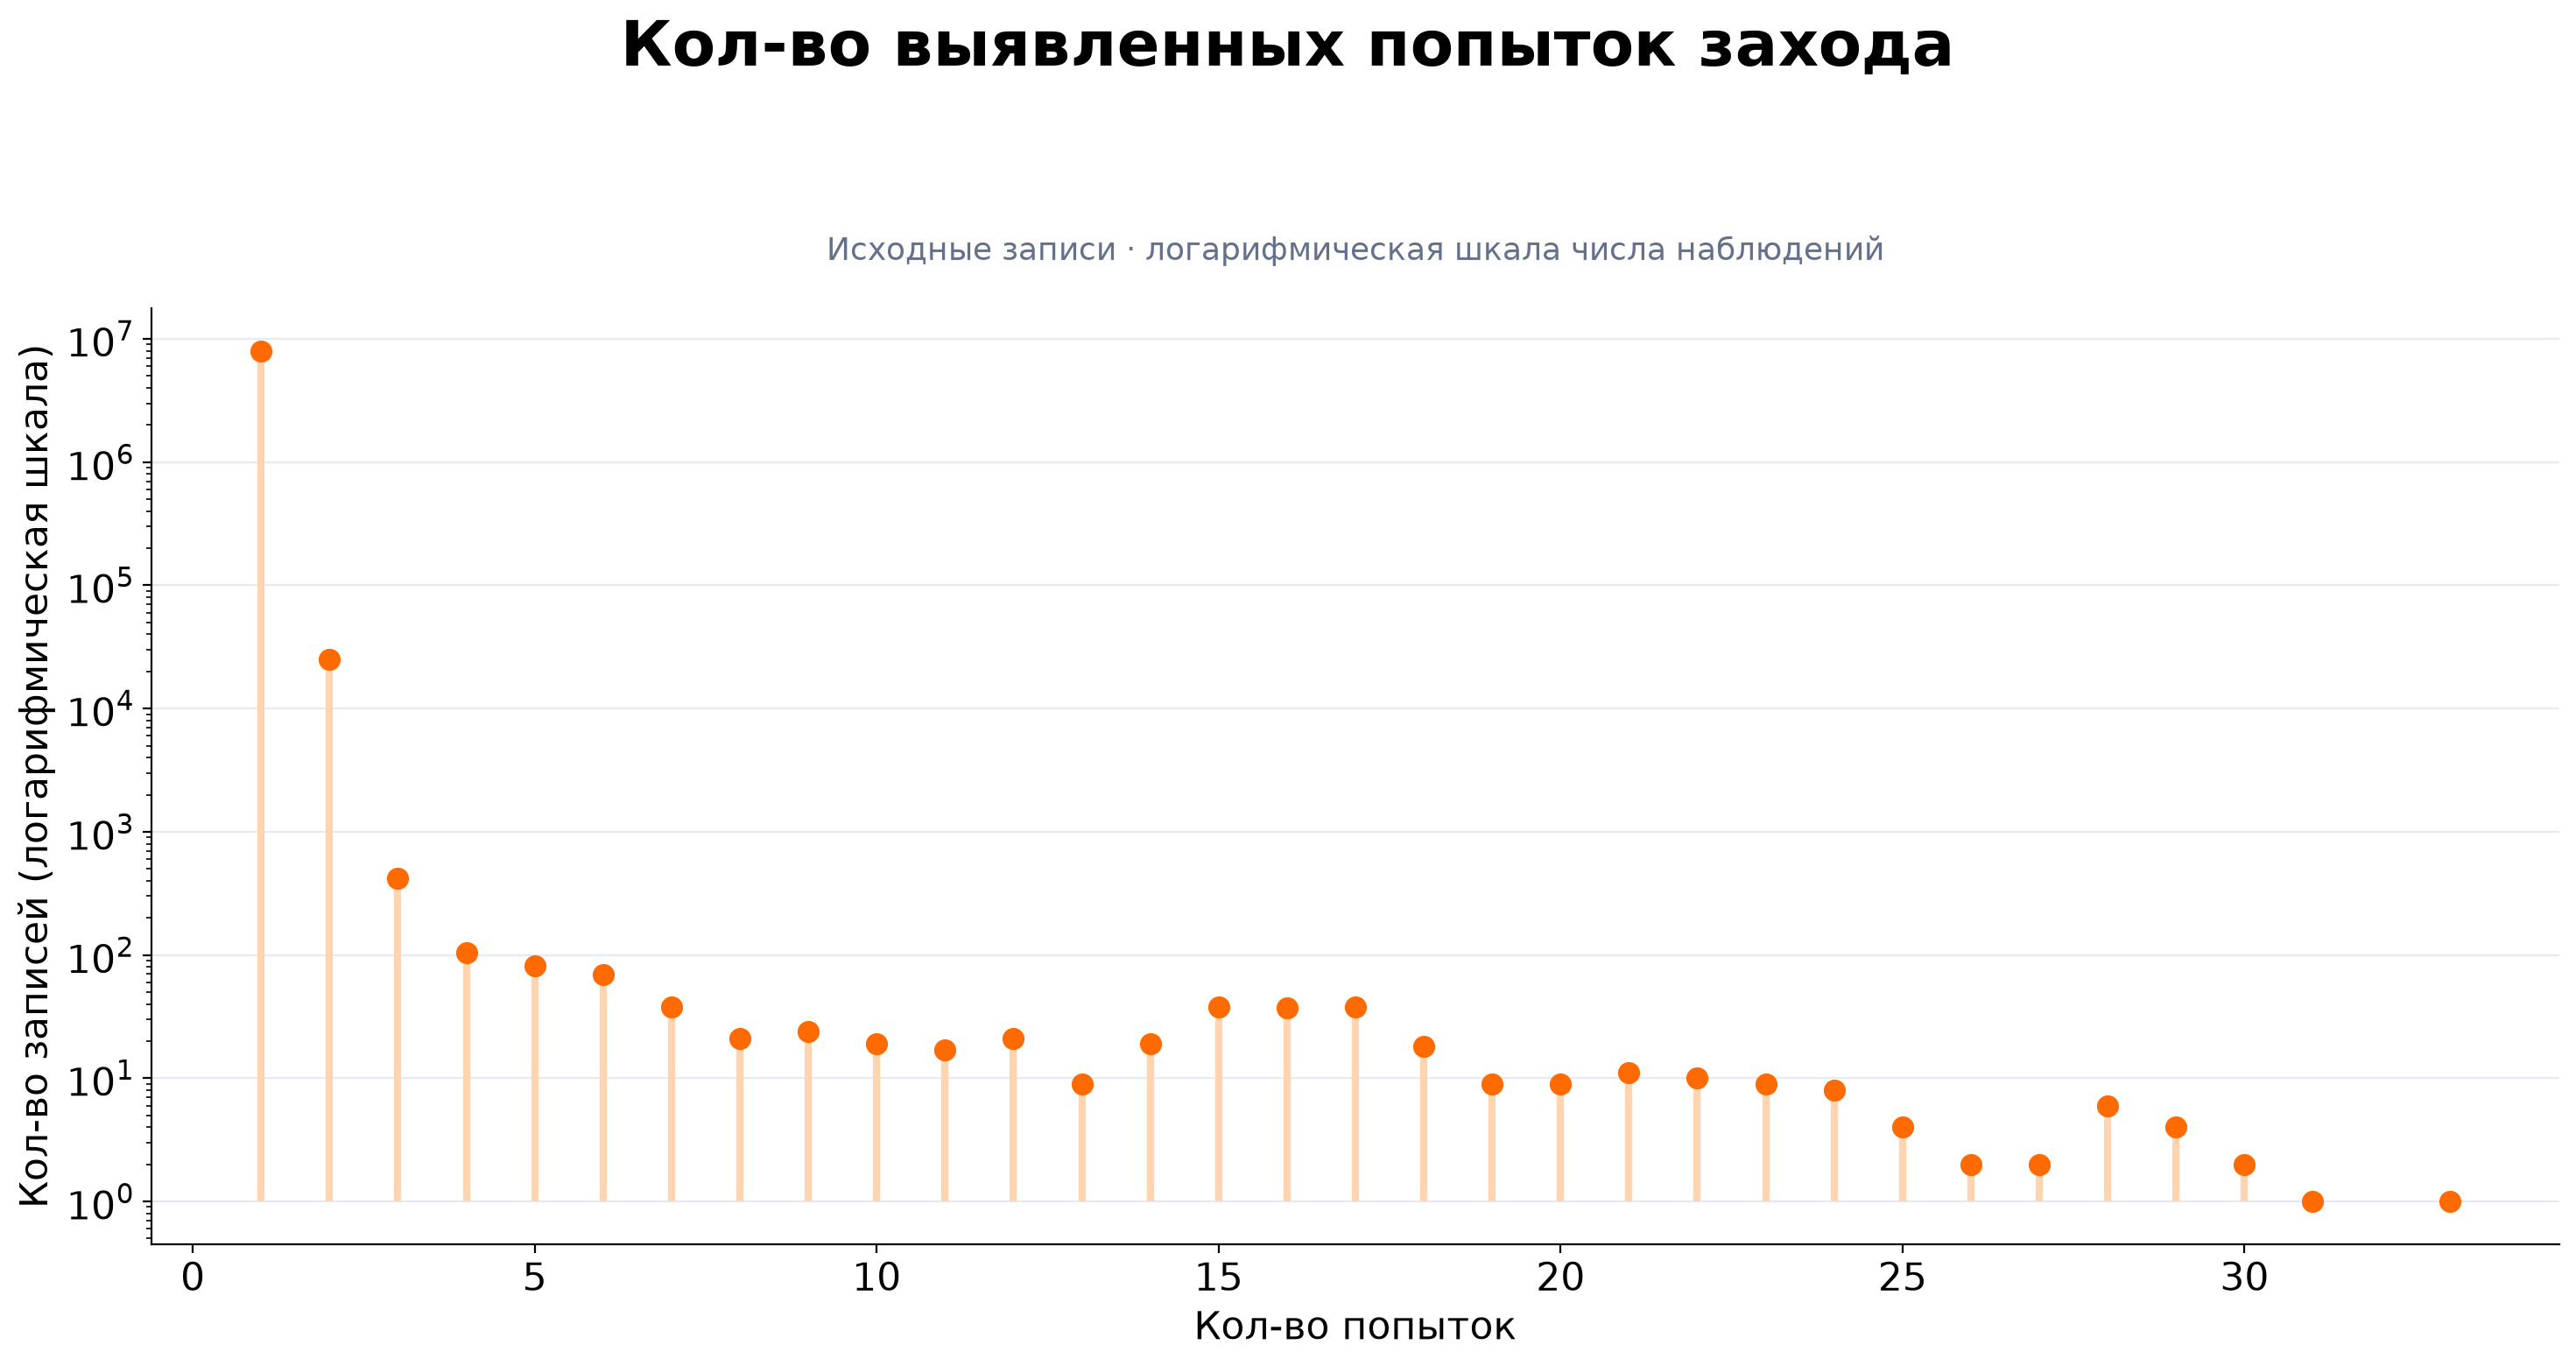

In [11]:
attempts=read('attempts_summary.csv')
fig,ax=chart('Кол-во выявленных попыток захода','Исходные записи · логарифмическая шкала числа наблюдений')
ax.vlines(attempts['n_attempts'],1,attempts['rows'],color='#FFD4B0',lw=3);ax.scatter(attempts['n_attempts'],attempts['rows'],color=ORANGE,s=65,zorder=3)
ax.set_yscale('log');ax.set_xlabel('Кол-во попыток');ax.set_ylabel('Кол-во записей (логарифмическая шкала)');ax.grid(axis='y',color='#E7EBF1')
save(fig,'10_attempt_counts')

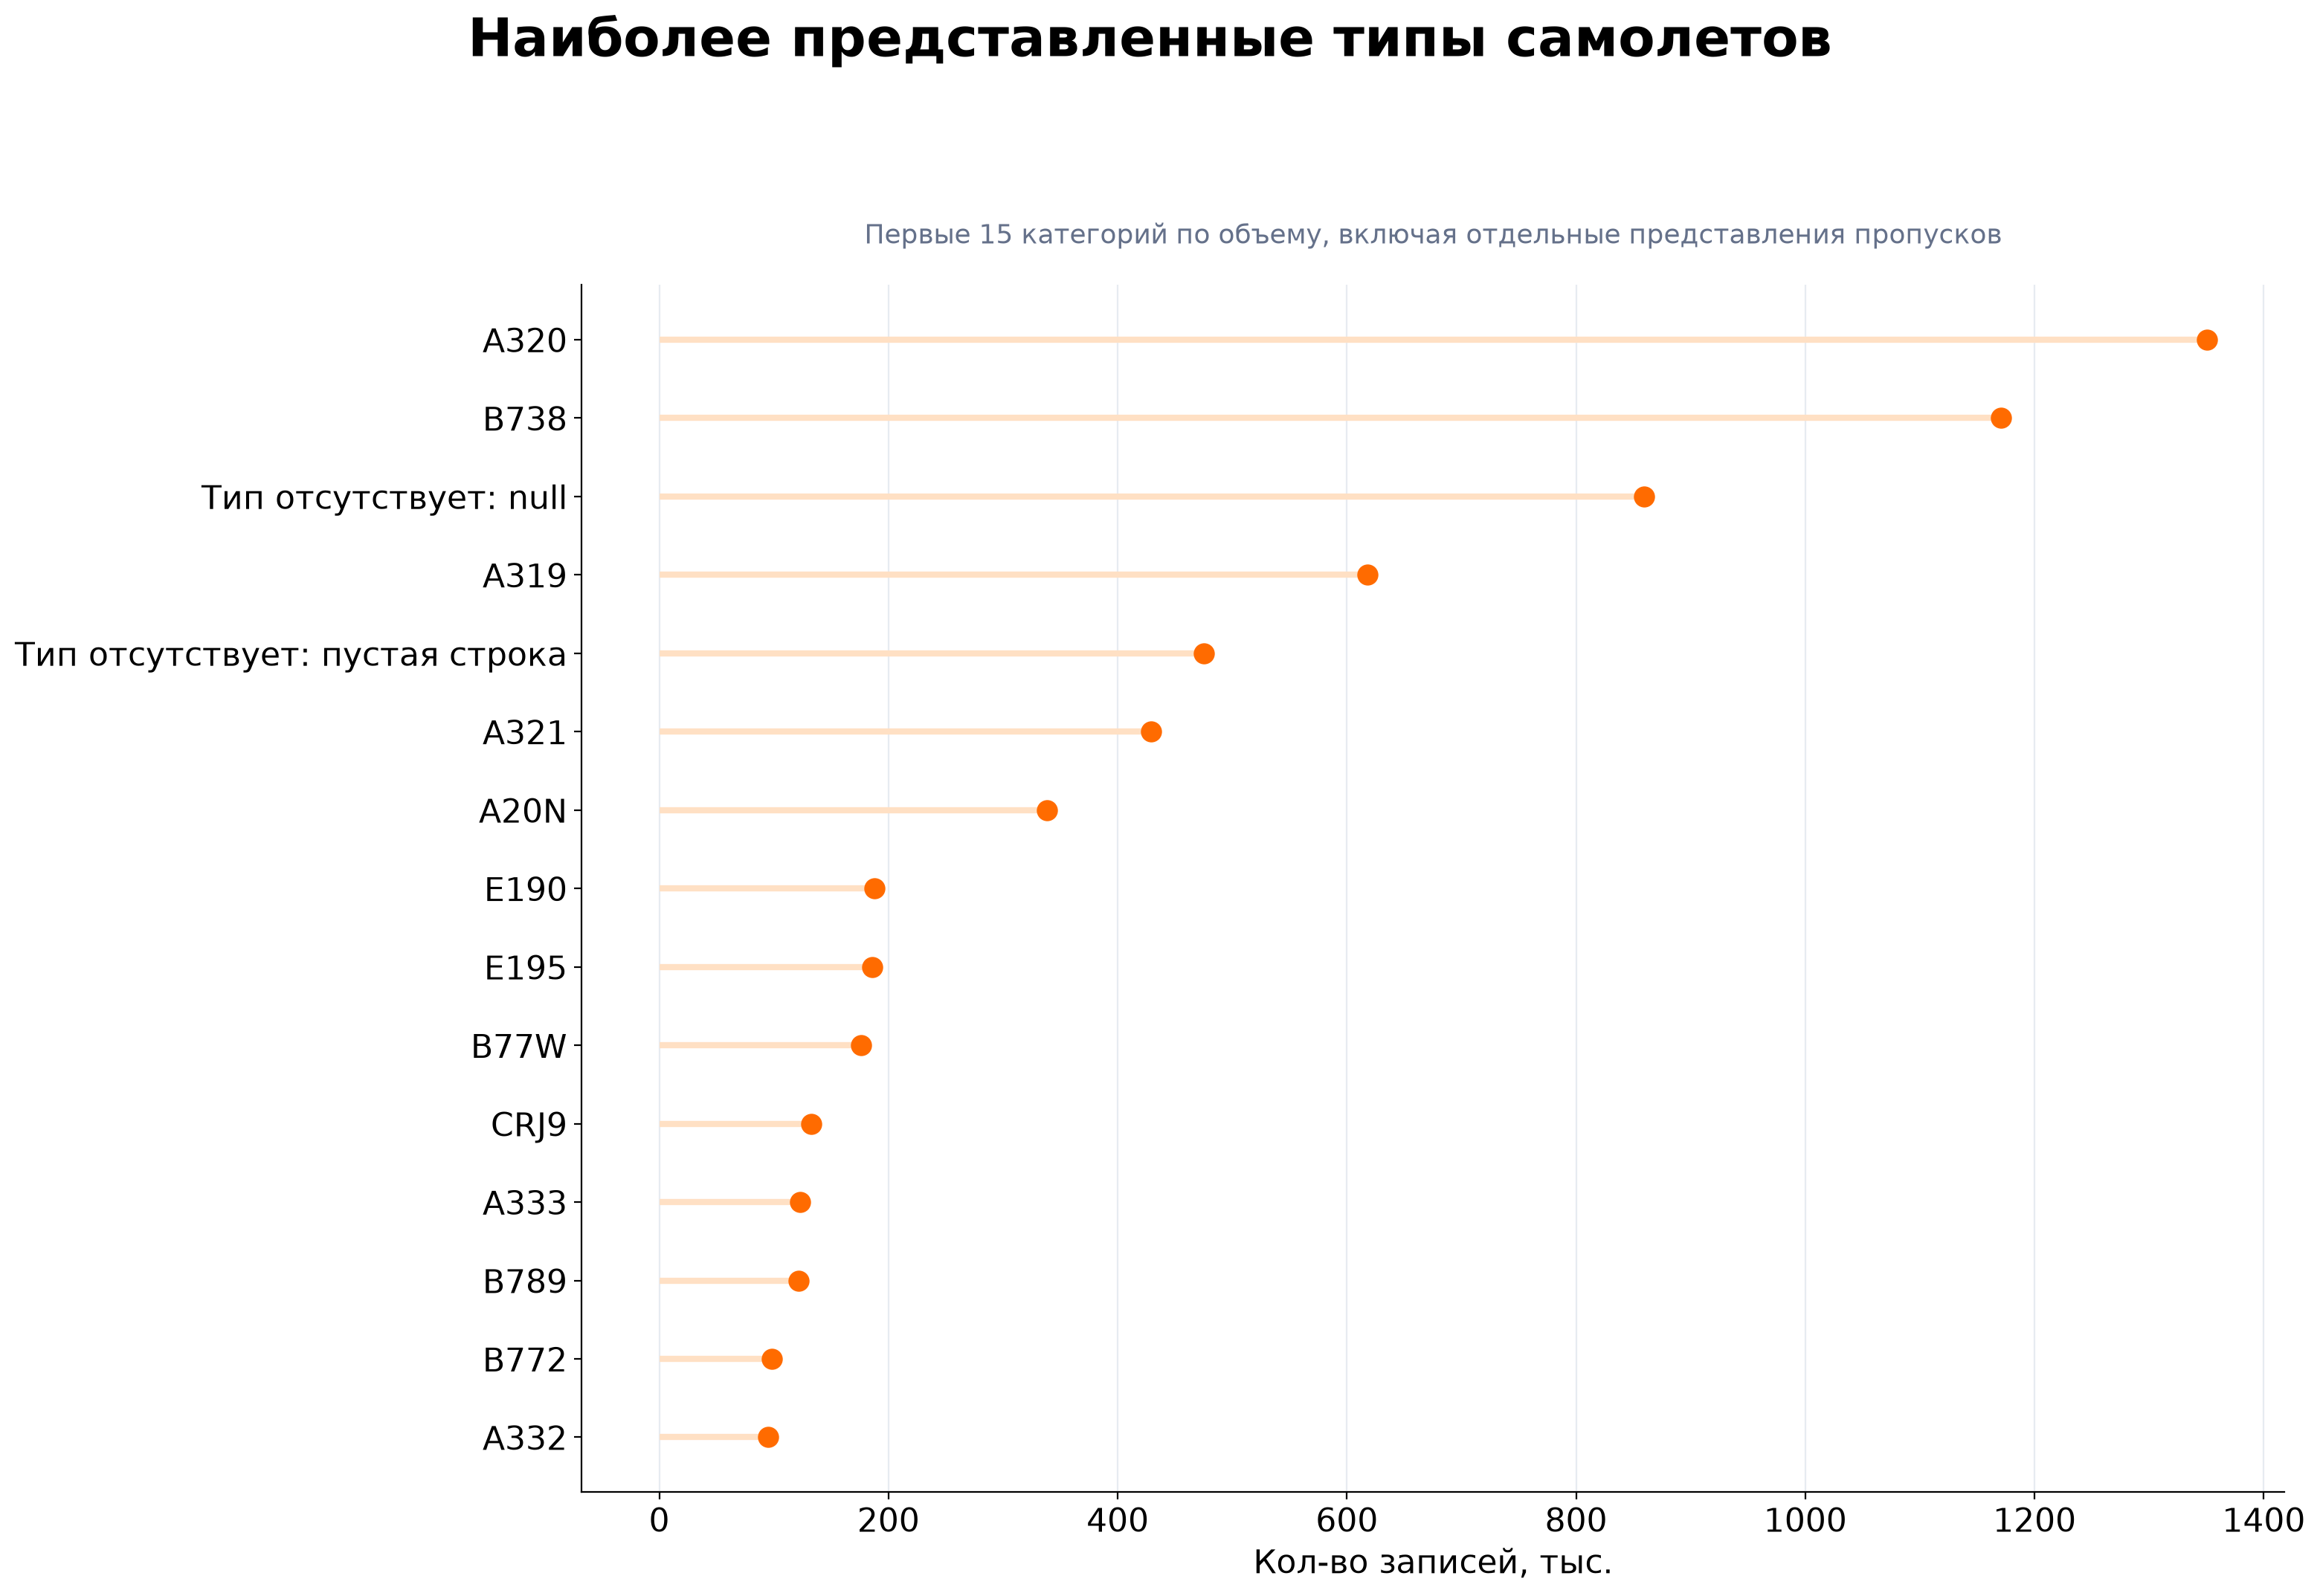

In [12]:
types=read('typecode_summary.csv').sort_values('rows',ascending=False).head(15).sort_values('rows')
names=types['typecode'].replace({'<NULL>':'Тип отсутствует: null','':'Тип отсутствует: пустая строка'})
fig,ax=chart('Наиболее представленные типы самолетов','Первые 15 категорий по объему, включая отдельные представления пропусков',size=(16,11))
ax.hlines(range(len(types)),0,types['rows']/1000,color='#FFE0C4',lw=3);ax.scatter(types['rows']/1000,range(len(types)),color=ORANGE,s=85,zorder=3)
ax.set_yticks(range(len(types)),names);ax.set_xlabel('Кол-во записей, тыс.');ax.grid(axis='x',color='#E7EBF1')
save(fig,'11_aircraft_types')

## Диагностические группы

Группы пересекаются. Их суммы не равны числу уникальных записей с флагами. Проверка преобладающего формата `icaoaircrafttype` является структурной диагностикой, а не авиационным нормативом. Ни одна группа автоматически не исключается.

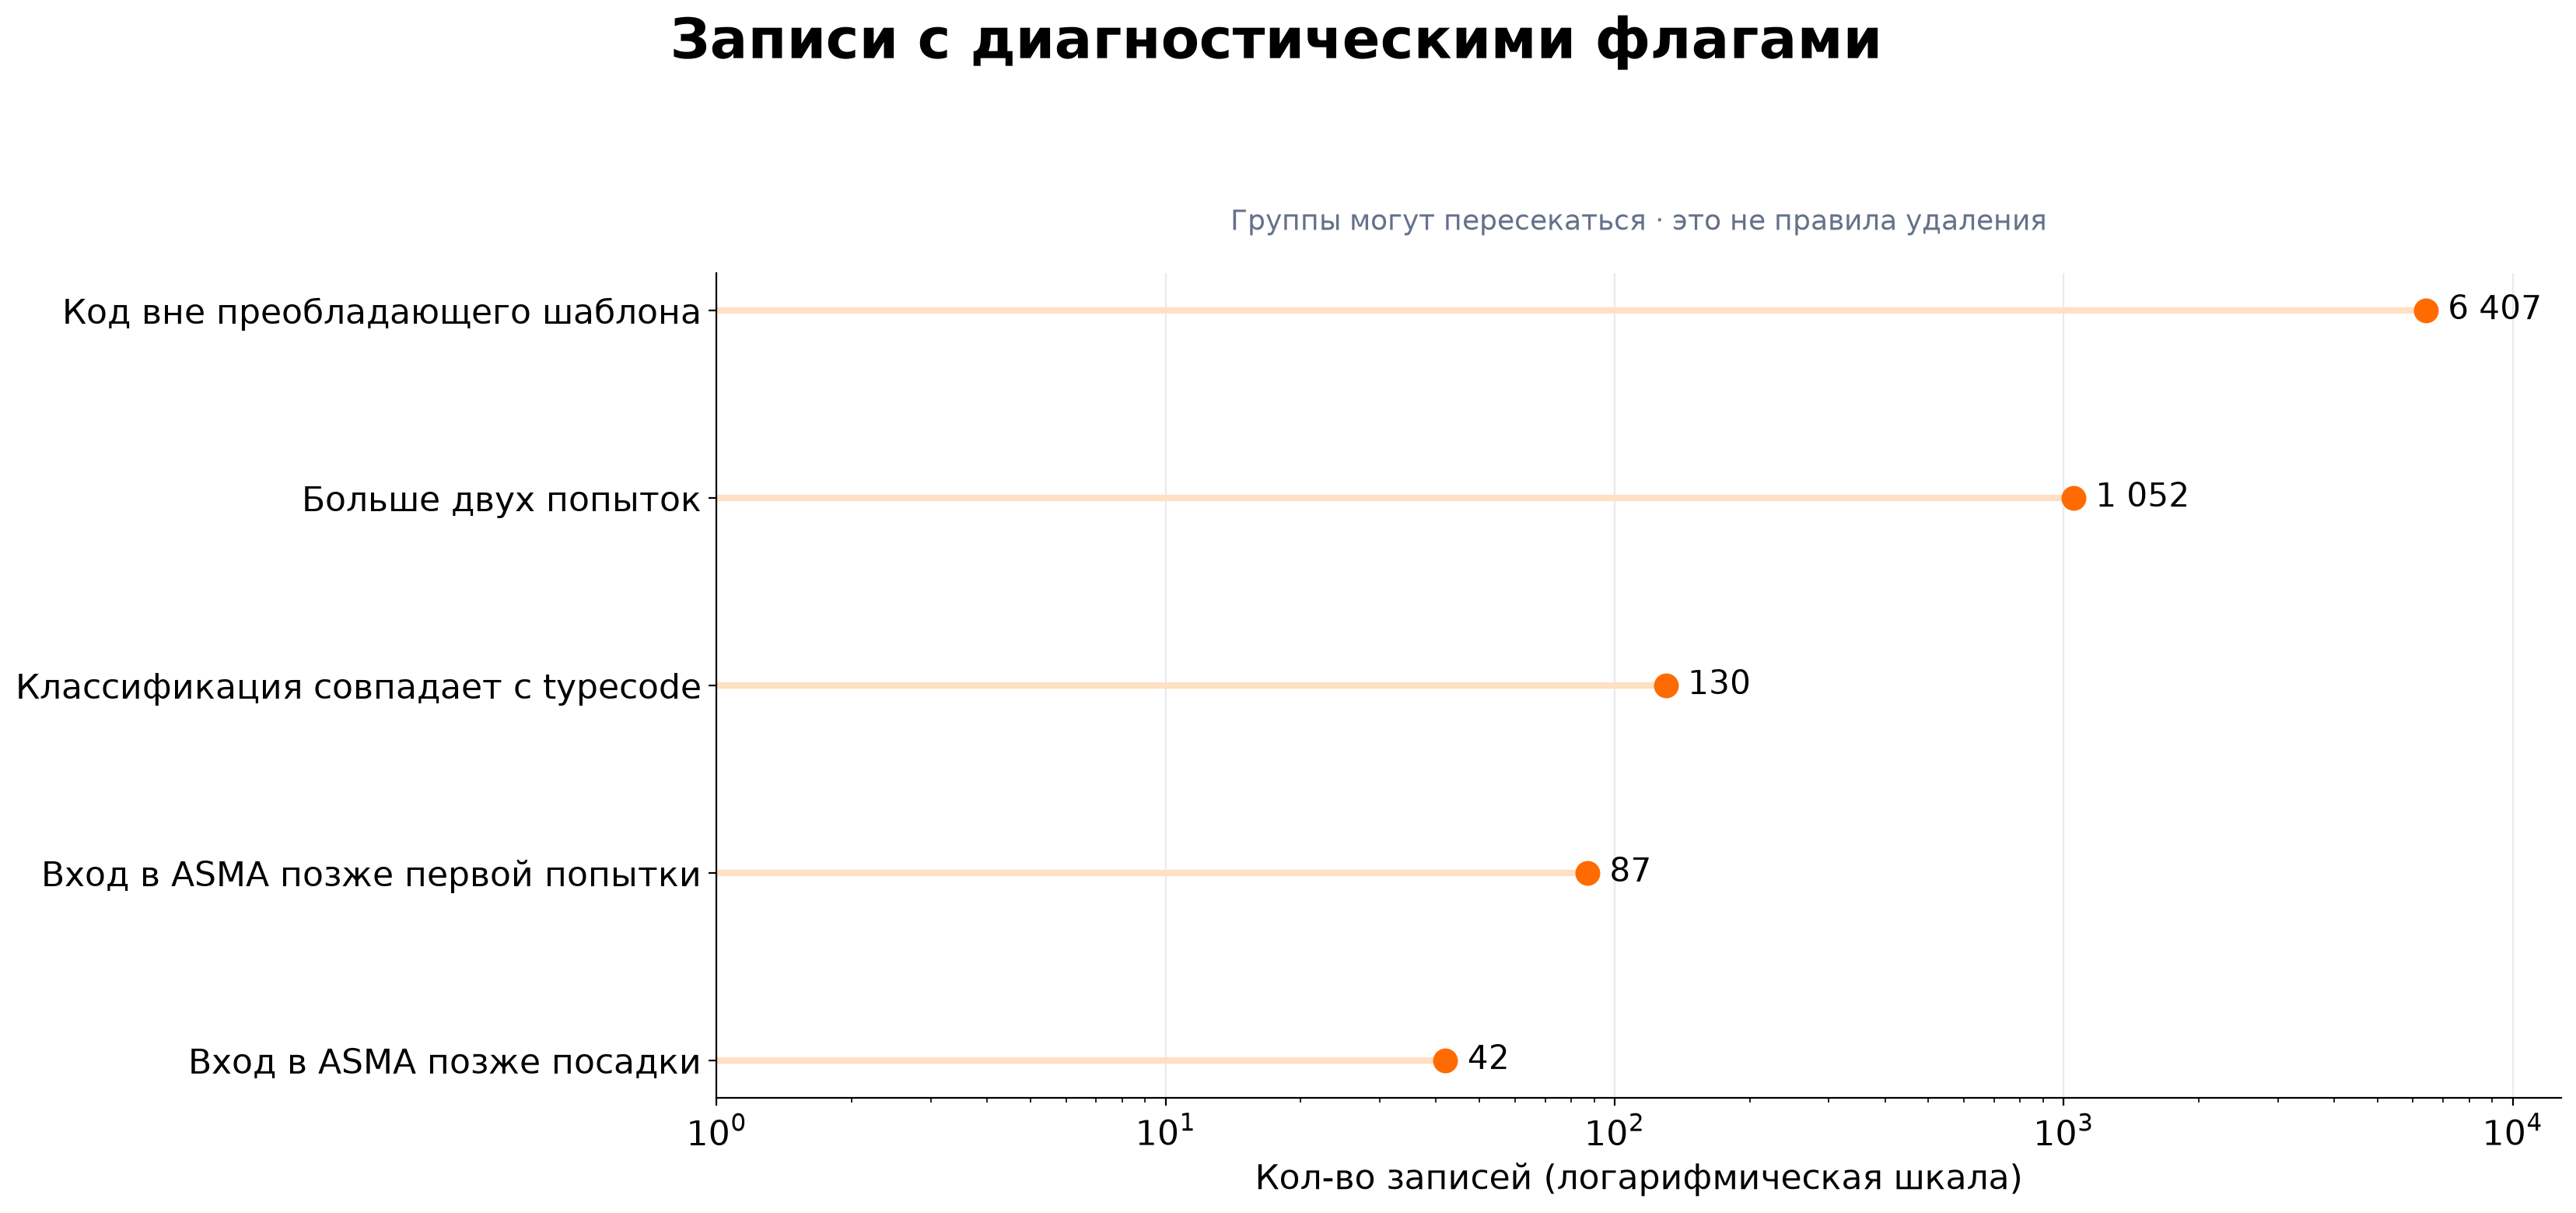

In [13]:
flags=read('review_flag_summary.csv');flags=flags.loc[flags['rows']>0].sort_values('rows')
translations={'icaoaircrafttype:outside_dominant_description_pattern':'Код вне преобладающего шаблона',
 'icaoaircrafttype:equals_typecode_ignoring_case':'Классификация совпадает с typecode',
 'n_attempts:more_than_two':'Больше двух попыток', 'C40_CROSS_TIME:after_first_attempt':'Вход в ASMA позже первой попытки',
 'C40_CROSS_TIME:after_landing':'Вход в ASMA позже посадки'}
fig,ax=chart('Записи с диагностическими флагами','Группы могут пересекаться · это не правила удаления',size=(17,8))
ax.hlines(range(len(flags)),1,flags['rows'],color='#FFE0C4',lw=3);ax.scatter(flags['rows'],range(len(flags)),color=ORANGE,s=110,zorder=3)
ax.set_yticks(range(len(flags)),flags['reason'].map(translations));ax.set_xscale('log');ax.set_xlim(1,flags['rows'].max()*2)
ax.set_xlabel('Кол-во записей (логарифмическая шкала)');ax.grid(axis='x',color='#E7EBF1')
for i,row in enumerate(flags.itertuples()):ax.text(row.rows*1.12,i,f'{int(row.rows):,}'.replace(',',' '),va='center',fontsize=15)
save(fig,'12_diagnostic_groups')

## Наблюдения для дальнейшего исследования

Отдельно рассматриваем чувствительность частот к временному покрытию, составу выборки и доступности обогащения. Численные различия ниже не являются доказательством причин. Математическую постановку, поправки на зависимость и возможность публикации нужно обсуждать отдельно.

In [14]:
display(pd.read_csv(V/'c40_availability.csv'))
print('Совпадают маски null в AC_CLASS и полях C40:',extra['joint_null_mask_equal_AC_CLASS_C40'])
print('Дней без записей сразу во всех 20 аэропортах:',len(extra['days_without_records_at_all_20_airports']))
print('Эти даты:',', '.join(extra['days_without_records_at_all_20_airports']))
print('Аэропорты с наибольшим числом отмеченных уходов в феврале 2020:')
display(pd.read_csv(V/'february_2020.csv').head(5))
# Сравнение групп числа попыток – диагностическое, без изменения базы
sensitivity=pd.read_csv(V/'attempt_sensitivity.csv').groupby('multiple')[['rows','go_arounds']].sum()
sensitivity['ga_percent']=100*sensitivity['go_arounds']/sensitivity['rows'];display(sensitivity)
assert extra['rows_deleted']==0
assert len(list(FIGURES.glob('*.png')))==10 and len(list(FIGURES.glob('*.svg')))==10
print('Сохранено 10 графиков в PNG и SVG. Очистка не выполнялась.')

,c40_available,rows,go_arounds,ga_percent
0,False,1652382,7847,0.474890
1,True,6331872,18406,0.290688


Совпадают маски null в AC_CLASS и полях C40: True
Дней без записей сразу во всех 20 аэропортах: 21
Эти даты: 2022-08-31, 2022-11-03, 2022-11-09, 2022-11-18, 2022-11-23, 2022-12-04, 2022-12-15, 2022-12-18, 2022-12-21, 2022-12-22, 2022-12-23, 2022-12-24, 2022-12-25, 2022-12-26, 2022-12-27, 2022-12-28, 2022-12-29, 2022-12-30, 2022-12-31, 2023-01-02, 2023-02-23
Аэропорты с наибольшим числом отмеченных уходов в феврале 2020:


,airport,month,rows,go_arounds,ga_percent
0,EGLL,2020-02,17283,135,0.781114
1,EHAM,2020-02,15074,97,0.643492
2,LFPG,2020-02,16112,87,0.539970
3,LSZH,2020-02,8766,87,0.992471
4,EIDW,2020-02,7339,82,1.117318


,rows,go_arounds,ga_percent
multiple,,,
False,7983202,25201,0.315675
True,1052,1052,100.000000


Сохранено 10 графиков в PNG и SVG. Очистка не выполнялась.


Следующий этап – `03`: разбор диагностических групп, проверка источников и согласование обработки. До этого все графики описывают исходную выборку. Погода и причинные объяснения пока не добавлены.